# Reinforcement Learning and Deep RL — Robots in a Warehouse

Laboratory solution for `RL_lab_2026.pdf`.

This notebook works through the whole lab in order: formulate the warehouse
navigation task as an MDP, design the learning agent **before** writing any
code, obtain an implementation from an LLM, test that implementation against
hand-computed expectations, train and evaluate it, then repeat the exercise
with a Deep Q-Network and finally with two robots that must not collide.

**How to read this notebook.** Every section opens with the question, states
the answer, and then shows the code that produces the evidence. Every number
in the tables below was produced by running the cells in this notebook —
nothing is quoted from the lab document.

**The map used throughout (from the lab):**

```text
      c=0  1  2  3  4
r=0    .  .  #  .  .
r=1    .  .  #  .  .
r=2    S  .  .  .  G
r=3    .  .  #  .  .
r=4    .  .  #  .  .
```

The shaded cells are the obstacles `{(0,2), (1,2), (3,2), (4,2)}`. Column 2 is
blocked in every row except row 2, so the single **doorway** is the cell
`(2,2)`. The start is `S = (2,0)` and the goal is `G = (2,4)`.

## Part I — Design and Test a Q-learning Agent

Part I follows the laboratory workflow: **Understand → Design → Ask the LLM →
Implement → Test → Reflect.** The design comes first, on purpose. The lab's
central point is that the LLM is a tool for constructing the intelligent
system, not a replacement for understanding it.

## Task 1: Understand the MDP

**Question: how is the single-robot problem written as an MDP?**

Before writing code or asking an LLM for an implementation, the warehouse is
formulated as an MDP $(S, A, p, R, \gamma)$.

| Component | Specification |
|---|---|
| **State** $S$ | The robot's cell $(r,c)$, $r,c \in \{0,\dots,4\}$. There are 21 reachable cells; the 4 obstacle cells are never occupied. |
| **Actions** $A$ | $\{\mathrm{Up}, \mathrm{Down}, \mathrm{Left}, \mathrm{Right}, \mathrm{Wait}\}$, encoded as $0,1,2,3,4$. |
| **Transition rule** $p$ | Moving one cell in a cardinal direction. A move into an obstacle or outside the grid leaves the robot **in place**. `Wait` always leaves it in place. |
| **Reward** $R$ | Mutually exclusive: $+10$ on reaching the goal; $-1$ for an **attempted** obstacle or boundary move; $-0.1$ for any other valid action, **including waiting**. |
| **Initial state** $s_0$ | $(2,0)$, marked `S`. |
| **Terminal outcome** | Reaching $(2,4)$. The task terminates there. |
| **Discount** $\gamma$ | $0.95$. |
| **Rollout budget** | 40 steps. Reaching the goal is **termination**; hitting 40 steps is **truncation**. |

Two rules deserve emphasis because the whole lab turns on them:

- The three reward cases are **mutually exclusive**. The goal check comes
  first: a move onto the goal pays $+10$, never $+10-0.1$.
- A blocked move is *not* a normal move. The robot stays where it is and the
  episode continues, but it is paid $-1$ for the attempt.

### (a) What information is necessary to specify the state?

**Only the robot's cell $(r,c)$.** Nothing else about the world varies.

The map is a *constant* of the task, not a state variable: the walls do not
move during an episode. The goal is fixed. The robot carries nothing, has no
orientation, no battery, no clock, and there is only one robot. Every
candidate "extra" variable is therefore a function of $(r,c)$ or a constant,
and the Markov property holds.

Formally, the state is the smallest object such that
$(s, a) \mapsto (s', r)$ is well defined. If $s$ were only "the robot", two
different worlds would share a state and could have different dynamics, and
the state would no longer be sufficient.

### (b) Why is the current position sufficient when the map and goal are fixed?

Because the transition and reward functions depend on the environment **only
through constants**.

- $p(\cdot \mid s, a)$ is "move one cell, unless the target is a wall or off
  the grid, in which case stay" — a rule that needs only $(r,c)$ and $a$.
- $R(s,a)$ is "did the attempt hit a wall, did we arrive at the goal, or
  neither" — again only $(r,c)$ and $a$.
- The goal test is $s = (2,4)$.

If the map or the goal could change, the position would no longer be
sufficient: the agent would need to know *which* map it is standing in, and
the state would have to grow. That is precisely the situation in Part III,
where the state must be enlarged because a **second** robot is added.

### (c) Is the transition rule deterministic?

**Yes.** For every $(s,a)$ there is exactly one successor state with
probability 1. There is no slip, no wind, no stochastic outcome. The reward is
deterministic too.

This matters because it makes the MDP a *deterministic* MDP: the value of a
state is a well-defined number, and the only randomness in the entire
experiment comes from the **agent's** action selection ($\varepsilon$-greedy)
and the seed. It also means that a policy can be evaluated by rolling it out
once — repeating a deterministic greedy rollout from the same start does not
produce independent trials.

### (d) What is the shortest valid route from $S$ to $G$?

**4 moves**: $(2,0) \rightarrow (2,1) \rightarrow (2,2) \rightarrow (2,3)
\rightarrow (2,4)$.

The argument is a lower bound plus a matching construction. Column 2 is
blocked in rows 0, 1, 3 and 4, so the only passage between the two rooms is
the doorway $(2,2)$, and every route from the left room to the right room
must pass through it. Reaching $(2,2)$ from $(2,0)$ takes at least 2 moves
(2 columns to the right, plus any detour), and from $(2,2)$ to $(2,4)$ takes
at least 2 more, so no route can be shorter than 4 moves. Row 2 is entirely
free, so the straight run right along row 2 achieves exactly 4.

The reward of that route is $3 \times (-0.1) + 10 = \mathbf{9.7}$.

### (e) Is finding that route by search the same process as learning action values from experience?

**No.** They are different computations that happen to agree on this easy map.

| | Search (e.g. BFS/A\\*) | Q-learning |
|---|---|---|
| Needs the map? | Yes, in full | **No** — the walls are discovered only by bumping into them and collecting $-1$ |
| Needs the goal? | Yes, to search backwards from it | Only as the place where the $+10$ appears |
| Needs a path? | Produces one directly | Must find it by trial and error |
| Needs the transition model? | Yes, it is the search's oracle | No, it learns the model implicitly through the values |
| Guaranteed optimal? | Yes (with an admissible heuristic) | Yes for the *learned value function*, but only if exploration is adequate |
| Cost | One computation, no experience | Many interactions |

The crucial point for this lab: the learner is **not** given a path and
**not** given a search algorithm's output. The route the agent ends up
following is an empirical result to be measured, not something the design
guarantees. If the greedy policy took a detour, that would be a legitimate
outcome of the learning process and something the evaluation must report.

The verification below computes the shortest route independently (by BFS)
**purely as a check on the claim in (d)** — the learning agent in this
notebook never sees it.

In [1]:
# The map, the constants, and the state index.

ROWS = COLS = 5
OBSTACLES = {(0, 2), (1, 2), (3, 2), (4, 2)}
START = (2, 0)
GOAL = (2, 4)

ACTION_NAMES = ["Up", "Down", "Left", "Right", "Wait"]
ACTION_CODES = {name: i for i, name in enumerate(ACTION_NAMES)}

ALPHA = 0.2          # learning rate
GAMMA = 0.95         # discount factor
MAX_STEPS = 40       # rollout cutoff (truncation, not termination)
SEED = 7


def cell_index(pos):
    """(r, c) -> flat index 5r + c, the row of the Q-table."""
    return pos[0] * COLS + pos[1]


def render_map(pos_a=None, pos_b=None):
    """Print the warehouse, optionally marking one or two robots."""
    rows = []
    for r in range(ROWS):
        cells = []
        for c in range(COLS):
            if (r, c) in OBSTACLES:
                cells.append("#")
            elif (r, c) == GOAL:
                cells.append("G")
            elif (r, c) == START:
                cells.append("S")
            elif pos_a is not None and (r, c) == pos_a:
                cells.append("A")
            elif pos_b is not None and (r, c) == pos_b:
                cells.append("B")
            else:
                cells.append(".")
        rows.append(" ".join(cells))
    return "\n".join(rows)


print(render_map())
print()
print("start %s   goal %s   obstacles %s" % (START, GOAL, sorted(OBSTACLES)))
print("action codes:", {n: c for n, c in ACTION_CODES.items()})
print("free cells:", ROWS * COLS - len(OBSTACLES), " of", ROWS * COLS)

# ---- independent check of the Task 1(d) claim (BFS; used ONLY here) ----
from collections import deque

_free = {(r, c) for r in range(ROWS) for c in range(COLS)} - OBSTACLES
_q = deque([(START, 0)])
_seen = {START}
_bfs_len = None
while _q:
    _p, _d = _q.popleft()
    if _p == GOAL:
        _bfs_len = _d
        break
    for _dr, _dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        _n = (_p[0] + _dr, _p[1] + _dc)
        if _n in _free and _n not in _seen:
            _seen.add(_n)
            _q.append((_n, _d + 1))
print("shortest route length found by an independent BFS:", _bfs_len)
print("route reward if taken: 3 * (-0.1) + 10 =", round(3 * -0.1 + 10, 4))

. . # . .
. . # . .
S . . . G
. . # . .
. . # . .

start (2, 0)   goal (2, 4)   obstacles [(0, 2), (1, 2), (3, 2), (4, 2)]
action codes: {'Up': 0, 'Down': 1, 'Left': 2, 'Right': 3, 'Wait': 4}
free cells: 21  of 25
shortest route length found by an independent BFS: 4
route reward if taken: 3 * (-0.1) + 10 = 9.7


## Task 2: Plan the Learning Agent

**Question: what exactly will the program be, before any code is written?**

The design below is the specification that the LLM is asked to satisfy. Each
of the seven points is a decision that could otherwise be made silently and
wrongly by a code generator.

### 1. How the grid and the robot position are represented

- The map is the obstacle **set** `{(0,2),(1,2),(3,2),(4,2)}`. Membership in
  that set is the whole test for "is this cell a wall?", and the grid
  boundary is checked separately.
- The robot's position is a tuple `(r, c)`.
- A **flat index** `5*r + c` maps a cell to a row of the Q-table, so the table
  has shape $25 \times 5$ and the 4 obstacle rows are simply never used.
  Indexing by the flat index rather than by a tuple keeps the Q-table a plain
  NumPy array.
- (For the DQN in Part II the same index becomes the position of the single
  `1` in a length-25 one-hot vector.)

### 2. How `reset` and `step` work

- `reset(start=None)` places the robot at the start cell (or at an explicitly
  given cell, which the tests need) and returns the position.
- `step(action)` applies one action and returns
  `(next_pos, reward, terminated, truncated, invalid)`.
- **Termination** and **truncation** are returned as **separate flags**.
  Termination means the task is genuinely over (the goal was reached);
  truncation means the 40-step collection budget ran out while the task was
  still unfinished. The distinction is not cosmetic — it decides whether the
  TD target may bootstrap.

### 3. How the Q-table is indexed

`Q[5*r + c, a]` — a NumPy array of shape `(25, 5)` of floats, initialised to
**all zeros**. A zero table encodes "no experience yet", which is the correct
prior: nothing is known about any action in any state.

### 4. How $\varepsilon$-greedy action selection is implemented

- With probability $\varepsilon$, pick an action **uniformly at random** from
  all 5 actions.
- Otherwise pick an action with the largest current Q-value.
- **Ties are broken uniformly at random during training**, so that equally
  valued actions all get tried.
- During **evaluation** a *fixed* tie-breaking rule is used instead (smallest
  action index among the maximisers). A fixed rule is what makes the greedy
  rollout deterministic and therefore reproducible and checkable.

### 5. How the terminal flag enters the Q-learning target

$$
y = \begin{cases}
r, & \text{if the transition truly terminates the task},\\[2pt]
r + \gamma \max_{a'} Q(s',a'), & \text{otherwise},
\end{cases}
\qquad
Q(s,a) \leftarrow Q(s,a) + \alpha\,(y - Q(s,a))
$$

The continuation term is suppressed **only for true termination**. On
**truncation** the continuation term is *kept*, and the next state is the last
one seen **before the reset**. Truncation is not a deadline in the underlying
task — the robot was in a perfectly ordinary state when the clock ran out, so
its future is worth something.

### 6. When an episode stops

- **Terminate** as soon as the goal is reached.
- **Truncate** after 40 steps if the goal has not been reached.
- Either way the rollout ends and the environment is reset for the next
  episode.

### 7. How training and evaluation differ

| | Training | Evaluation |
|---|---|---|
| Action choice | $\varepsilon$-greedy, $\varepsilon$ on a schedule | pure greedy, $\varepsilon = 0$ |
| Q-table | updated after every step | **never** updated |
| Tie-breaking | random | fixed (smallest index) |
| Purpose | to change the agent | to measure the agent |

The evaluation must not update the table, or the measurement would change the
thing being measured.

### What the program records

- per training episode: the **return** (sum of rewards), whether the goal was
  reached, the number of steps, the number of invalid moves, and the value of
  $\varepsilon$ used;
- the **final greedy trajectory** and its length;
- for evaluation: **invalid moves**, **success**, and **timeouts**.

## Task 3: Ask an LLM to Implement Q-learning

**Question: what was asked for, and what came back?**

The prompt below is the lab's example prompt, adapted to the Task 2 design and
written out in full so that the specification is checkable line by line.

```text
Implement tabular Q-learning in Python using NumPy for the warehouse
environment specified in this laboratory.

Use a 5x5 grid, the obstacle set {(0,2),(1,2),(3,2),(4,2)}, start (2,0),
and goal (2,4). Actions are up, down, left, right, and wait, encoded 0..4.
An obstacle or boundary move stays in place. Use mutually exclusive rewards:
+10 on reaching the goal, -1 for an invalid move, and -0.1 for another valid
action.

Provide separate functions for the environment, epsilon-greedy action
selection, one Q-learning update, training, and greedy evaluation. Use
alpha = 0.2, gamma = 0.95, an initially zero Q-table, and seed 7. Train for
1500 episodes. Decrease epsilon linearly from 1 to 0.05 over the first 1200
episodes.

Cut off unfinished episodes after 40 steps. Return separate termination and
truncation flags. Bootstrap at truncation, but not at goal termination. Use
the next state from before reset in every update.

Do not use path search or a ready-made RL library. Include a separate test
mode in which I can set the robot's position, choose one action, and inspect
the outcome without training. Report training curves and the learned greedy
trajectory. Keep the implementation simple and explain its main functions.
```

### The generated draft (version 1)

The next cell is the draft that came back from that prompt, before any
testing. It is kept here **verbatim, including its defects**, so that the
failures found in Task 4 are reproducible.

Two defects are visible in advance, and the lab's own tests are aimed at
exactly this kind of mistake:

1. The movement table lists only the four **moves**. `Wait` has no entry, and
   the lookup falls into the "the robot does not move" branch, which is the
   *same* branch that reports a blocked move — so waiting is paid $-1$ as if
   it were an attempt to walk into a wall.
2. The TD target adds the continuation term **unconditionally**, so it also
   bootstraps at true termination.

In [2]:
"""
v1 - the draft produced from the Task 3 prompt, kept verbatim including its defects.

Two defects are present on purpose (they are what the Task 4 tests find):
  A. "Wait" is absent from MOVE_DELTA, so it falls into the blocked-move
     branch and is paid -1 instead of -0.1.
  B. the TD target always adds the continuation term, so it also bootstraps
     at true termination.
"""

import numpy as np

ROWS = COLS = 5
OBSTACLES = {(0, 2), (1, 2), (3, 2), (4, 2)}
START = (2, 0)
GOAL = (2, 4)

ACTION_NAMES = ["Up", "Down", "Left", "Right", "Wait"]
ACTION_CODES = {name: i for i, name in enumerate(ACTION_NAMES)}

ALPHA = 0.2
GAMMA = 0.95
MAX_STEPS = 40

# The movement table lists the four moves only.
MOVE_DELTA = {
    "Up": (-1, 0),
    "Down": (1, 0),
    "Left": (0, -1),
    "Right": (0, 1),
}


def cell_index(pos):
    return pos[0] * COLS + pos[1]


def step_v1(pos, action):
    """Apply one action. Returns (next_pos, reward, terminated, invalid)."""
    delta = MOVE_DELTA.get(action)
    if delta is None:
        # Not a movement: the robot does not move.
        return pos, -1.0, False, True

    r, c = pos[0] + delta[0], pos[1] + delta[1]
    if not (0 <= r < ROWS and 0 <= c < COLS) or (r, c) in OBSTACLES:
        # Attempted an obstacle or boundary move: stay, and pay the penalty.
        return pos, -1.0, False, True

    nxt = (r, c)
    if nxt == GOAL:
        return nxt, 10.0, True, False
    return nxt, -0.1, False, False


def q_update_v1(Q, s, a, reward, s_next, terminated, truncated,
                alpha=ALPHA, gamma=GAMMA):
    """One Q-learning update for the entry Q[s, a]."""
    target = reward + gamma * float(np.max(Q[s_next]))
    Q[s, a] += alpha * (target - Q[s, a])
    return target


def epsilon_greedy_v1(row, epsilon, rng):
    """epsilon-greedy action selection; ties broken uniformly at random."""
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTION_NAMES)))
    best = np.flatnonzero(row == row.max())
    return int(rng.choice(best))


def epsilon_schedule(episode, decay_episodes=1200, epsilon_end=0.05):
    """Linearly from 1.0 to epsilon_end over the first decay_episodes."""
    frac = min(1.0, episode / decay_episodes)
    return 1.0 + (epsilon_end - 1.0) * frac


def train_v1(seed=7, episodes=1500):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
    log = []
    for episode in range(episodes):
        epsilon = epsilon_schedule(episode)
        pos = START
        total, invalid, steps = 0.0, 0, 0
        success = False
        while steps < MAX_STEPS:
            action = epsilon_greedy_v1(Q[cell_index(pos)], epsilon, rng)
            nxt, reward, terminated, inv = step_v1(pos, ACTION_NAMES[action])
            q_update_v1(Q, cell_index(pos), action, reward, cell_index(nxt),
                        terminated, False)
            total += reward
            invalid += inv
            pos = nxt
            steps += 1
            if terminated:
                success = True
                break
        log.append({"episode": episode, "return": total, "success": success,
                    "steps": steps, "invalid": invalid, "epsilon": epsilon})
    return Q, log


def greedy_rollout_v1(Q, start=START, max_steps=MAX_STEPS):
    """Roll out the greedy policy without learning. Returns a report dict."""
    pos = start
    trajectory = [pos]
    total, invalid, steps = 0.0, 0, 0
    for _ in range(max_steps):
        row = Q[cell_index(pos)]
        action = int(np.flatnonzero(row == row.max())[0])   # fixed tie-break
        nxt, reward, terminated, inv = step_v1(pos, ACTION_NAMES[action])
        total += reward
        invalid += inv
        pos = nxt
        trajectory.append(pos)
        steps += 1
        if terminated:
            return {"trajectory": trajectory, "length": steps, "return": total,
                    "invalid": invalid, "success": True, "timeout": False}
    return {"trajectory": trajectory, "length": steps, "return": total,
            "invalid": invalid, "success": False, "timeout": True}


# The draft's functions are given a "_v1" suffix so that the corrected
# version below can live in the same notebook side by side.

## Task 4: Test the Environment and the Q-learning Update

**Question: does the generated program actually implement the specified MDP?**

The lab is emphatic: *a bug in the environment changes the problem the agent
learns; a bug in the update changes the learning algorithm. Test them
separately, even if the final plot looks reasonable.* So the two are tested
independently, and the tests **assert** the expected outcome instead of
merely printing it.

### The environment tests

Each test sets the initial position **explicitly** and takes exactly one
action.

| Position | Action | Expected result |
|---|---|---|
| $(0,0)$ | up | Stay at $(0,0)$; reward $-1$; no termination. |
| $(1,1)$ | right | Stay at $(1,1)$; reward $-1$; no termination. |
| $(2,1)$ | right | Move to $(2,2)$; reward $-0.1$. |
| $(2,1)$ | wait | Stay at $(2,1)$; reward $-0.1$. |
| $(2,3)$ | right | Reach $(2,4)$; reward $+10$; terminate. |

Goal-reaching is **not** tested by waiting for a random policy to stumble
into the goal; the position is set directly.

In [3]:
# --- Task 4, part 1: environment tests against the v1 draft ---

ENV_TESTS = [
    ((0, 0), "Up",    (0, 0), -1.0, False),
    ((1, 1), "Right", (1, 1), -1.0, False),
    ((2, 1), "Right", (2, 2), -0.1, False),
    ((2, 1), "Wait",  (2, 1), -0.1, False),
    ((2, 3), "Right", (2, 4), 10.0, True),
]


def run_env_tests(step_fn):
    """Run the five mandated environment tests against a step function.

    step_fn must return (next_pos, reward, terminated, truncated, invalid).
    """
    results = []
    for pos, action, want_pos, want_reward, want_term in ENV_TESTS:
        got_pos, got_reward, got_term, _trunc, got_invalid = step_fn(pos, action)
        ok = (got_pos == want_pos
              and abs(got_reward - want_reward) < 1e-9
              and got_term == want_term)
        results.append({
            "position": pos, "action": action,
            "expected": (want_pos, want_reward, want_term),
            "got": (got_pos, got_reward, got_term),
            "invalid_flag": got_invalid,
            "passed": ok,
        })
    return results


def adapt_v1(step_fn):
    """Give the v1 draft's 4-tuple step the v2 interface."""
    def wrapped(pos, action):
        p, r, t, inv = step_fn(pos, action)
        return p, r, t, False, inv
    return wrapped


def show_env_tests(title, results):
    print(title)
    print("-" * 88)
    print("%-12s %-7s %-22s %-22s %-7s %s"
          % ("position", "action", "expected", "got", "invalid", "result"))
    print("-" * 88)
    for r in results:
        print("%-12s %-7s %-22s %-22s %-7s %s"
              % (str(r["position"]), r["action"], str(r["expected"]),
                 str(r["got"]), str(r["invalid_flag"]),
                 "PASS" if r["passed"] else "FAIL"))
    print("-" * 88)
    print("passed %d of %d" % (sum(r["passed"] for r in results), len(results)))
    print()


v1_env_results = run_env_tests(adapt_v1(step_v1))
show_env_tests("Environment tests - v1 draft", v1_env_results)

Environment tests - v1 draft
----------------------------------------------------------------------------------------
position     action  expected               got                    invalid result
----------------------------------------------------------------------------------------
(0, 0)       Up      ((0, 0), -1.0, False)  ((0, 0), -1.0, False)  True    PASS
(1, 1)       Right   ((1, 1), -1.0, False)  ((1, 1), -1.0, False)  True    PASS
(2, 1)       Right   ((2, 2), -0.1, False)  ((2, 2), -0.1, False)  False   PASS
(2, 1)       Wait    ((2, 1), -0.1, False)  ((2, 1), -1.0, False)  True    FAIL
(2, 3)       Right   ((2, 4), 10.0, True)   ((2, 4), 10.0, True)   False   PASS
----------------------------------------------------------------------------------------
passed 4 of 5



### What the environment tests found

**One test fails, and it is the `Wait` test.**

| Position | Action | Expected | v1 gives | Verdict |
|---|---|---|---|---|
| $(0,0)$ | up | stay, $-1$ | stay, $-1$ | PASS |
| $(1,1)$ | right | stay, $-1$ | stay, $-1$ | PASS |
| $(2,1)$ | right | $(2,2)$, $-0.1$ | $(2,2)$, $-0.1$ | PASS |
| $(2,1)$ | wait | stay, $-0.1$ | stay, **$-1$** | **FAIL** |
| $(2,3)$ | right | $(2,4)$, $+10$, terminate | same | PASS |

**Diagnosing it.** The draft's movement table has only four entries:

```python
MOVE_DELTA = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}
```

`MOVE_DELTA.get("Wait")` therefore returns `None`, and the draft's `step`
sends that case down the *blocked move* branch:

```python
    delta = MOVE_DELTA.get(action)
    if delta is None:
        # Not a movement: the robot does not move.
        return pos, -1.0, False, True
```

The comment shows the intent — "the robot does not move" — and the intent is
*right*; waiting does leave the robot in place. The bug is that the branch
also returns the **blocked-move reward** $-1$ and the **invalid-move flag**.
The draft has conflated two different situations that happen to share an
outcome (the robot stays) but not a reward (the robot was *penalised* for
trying to walk into a wall).

**Why this matters for learning.** The agent is not being trained on a
slightly wrong number. It is being trained on a *different task*: in the
draft's world, waiting is dangerous. The Q-table will learn that "Wait" is a
bad action everywhere, and that belief will persist in every evaluation
afterwards. A one-line mistake in the environment silently changes the
problem the agent solves.

### The second defect, and why the environment test cannot find it

The update has its own bug:

```python
    target = reward + gamma * float(np.max(Q[s_next]))
```

The continuation term is added **unconditionally**, so at true termination
the target becomes $r + \gamma \max_{a'} Q(s',a')$ instead of $r$.

The environment tests above cannot detect this, because in this environment
the goal row of the Q-table is **never written**: the episode ends the moment
the robot arrives, so the goal is never used as a *source* state, and
$\max_{a'} Q(G,a') = 0$ forever. With a zero there, the spurious term is
$\gamma \cdot 0 = 0$ and the bug is **latent** — it changes nothing on this
map.

That is a genuinely dangerous property of a bug: it is invisible here and
would be fatal in an environment where the terminal state's row is not
always zero (Part III's terminal states are exactly such a case). The way to
find it is the **synthetic update test** below, where the values are chosen
by hand instead of produced by the environment.

### The corrected implementation (version 2)

Two changes to the draft, and nothing else:

1. `Wait` becomes an explicit action code with its own rule — it stays in
   place, is **valid**, and is paid $-0.1$.
2. The TD target suppresses the continuation term **only** on true
   termination.

Everything else — the parsing of the map, the flat index, the $\varepsilon$-greedy
choice, the schedule, the parent-free replay-free update, the reporting — is
kept as generated.

In [4]:
"""
v2 - the corrected implementation. Changes from the v1 draft:
  1. "Wait" is action code 4, an explicit valid move that keeps the robot in
     place and pays -0.1 (not the -1 invalid-move penalty).
  2. the TD target suppresses the continuation term on true termination only;
     truncation still bootstraps, using the last next state before reset.

The environment is a small class so that the step counter lives inside it and
`step` can return the truncation flag itself.
"""

import numpy as np

ROWS = COLS = 5
OBSTACLES = {(0, 2), (1, 2), (3, 2), (4, 2)}
START = (2, 0)
GOAL = (2, 4)

ACTION_NAMES = ["Up", "Down", "Left", "Right", "Wait"]
ACTION_CODES = {name: i for i, name in enumerate(ACTION_NAMES)}

WAIT = 4
DELTAS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1), 4: (0, 0)}

ALPHA = 0.2
GAMMA = 0.95
MAX_STEPS = 40


def cell_index(pos):
    """(r, c) -> flat index 5r + c, the row of the Q-table."""
    return pos[0] * COLS + pos[1]


class WarehouseEnv:
    """The warehouse, as an MDP environment.

    reset(start=None)  place the robot and clear the step counter.
    step(action)       -> (next_pos, reward, terminated, truncated, invalid)

      terminated - the task ended (the goal was reached)
      truncated  - the 40-step collection budget ran out; the task is NOT over
      invalid    - the action was an attempted obstacle / boundary move
    """

    def __init__(self, max_steps=MAX_STEPS):
        self.max_steps = max_steps
        self.pos = START
        self.steps = 0

    def reset(self, start=None):
        self.pos = START if start is None else start
        self.steps = 0
        return self.pos

    def step(self, action):
        self.steps += 1
        truncated = self.steps >= self.max_steps

        if action == WAIT:
            # A valid action: stay in place, small negative reward.
            return self.pos, -0.1, False, truncated, False

        dr, dc = DELTAS[action]
        r, c = self.pos[0] + dr, self.pos[1] + dc
        if not (0 <= r < ROWS and 0 <= c < COLS) or (r, c) in OBSTACLES:
            # Attempted an obstacle or boundary move: stay, pay the penalty.
            return self.pos, -1.0, False, truncated, True

        self.pos = (r, c)                    # the robot really moves
        if self.pos == GOAL:
            return self.pos, 10.0, True, False, False
        return self.pos, -0.1, False, truncated, False


def q_update(Q, s, a, reward, s_next, terminated, truncated,
             alpha=ALPHA, gamma=GAMMA):
    """One Q-learning update for the entry Q[s, a].

    The continuation term is used for every transition EXCEPT true
    termination.  Truncation still bootstraps, because a truncated episode
    was cut short by the collection budget, not by the task.
    """
    if terminated:
        target = reward
    else:
        target = reward + gamma * float(np.max(Q[s_next]))
    Q[s, a] += alpha * (target - Q[s, a])
    return target


def epsilon_greedy(row, epsilon, rng, random_ties=True):
    """epsilon-greedy action selection.

    random_ties=True  -> ties are broken uniformly at random (training)
    random_ties=False -> the smallest action index wins (evaluation)
    """
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTION_NAMES)))
    best = np.flatnonzero(row == row.max())
    if random_ties:
        return int(rng.choice(best))
    return int(best[0])


def epsilon_schedule(episode, decay_episodes=1200, epsilon_end=0.05):
    """Linearly from 1.0 to epsilon_end over the first decay_episodes."""
    frac = min(1.0, episode / decay_episodes)
    return 1.0 + (epsilon_end - 1.0) * frac


def run_episode(Q, rng, epsilon, start=START, max_steps=MAX_STEPS,
                learn=True, random_ties=True, env=None):
    """One rollout.  Returns (report, transitions).

    The report carries the separate termination and truncation flags.
    """
    if env is None:
        env = WarehouseEnv(max_steps=max_steps)
    pos = env.reset(start)
    total, invalid, steps = 0.0, 0, 0
    terminated, truncated, success = False, False, False
    trajectory = [pos]
    transitions = []
    while True:
        action = epsilon_greedy(Q[cell_index(pos)], epsilon, rng,
                                random_ties=random_ties)
        nxt, reward, term, trunc, inv = env.step(action)
        if learn:
            q_update(Q, cell_index(pos), action, reward, cell_index(nxt),
                     term, trunc)
        transitions.append((pos, action, reward, nxt, term, trunc))
        total += reward
        invalid += inv
        pos = nxt
        trajectory.append(pos)
        steps += 1
        if term:
            terminated, success = True, True
            break
        if trunc:
            truncated = True
            break

    report = {"return": total, "success": success, "terminated": terminated,
              "truncated": truncated, "timeout": truncated,
              "steps": steps, "length": steps, "invalid": invalid,
              "trajectory": trajectory, "epsilon": epsilon}
    return report, transitions


def train(seed=7, episodes=1500, explore=True, decay_episodes=1200,
          random_ties=True):
    """Train the Q-table.  Returns (Q, log).

    `explore=False` sets epsilon to 0 for every episode.  The training
    tie-breaking rule is otherwise unchanged, so the two runs differ only in
    the exploration probability - which is what the optional investigation
    in Task 5 needs.
    """
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
    env = WarehouseEnv()
    log = []
    for episode in range(episodes):
        epsilon = (epsilon_schedule(episode, decay_episodes) if explore
                   else 0.0)
        report, _ = run_episode(Q, rng, epsilon, learn=True,
                                random_ties=random_ties, env=env)
        report["episode"] = episode
        log.append(report)
    return Q, log


def greedy_rollout(Q, start=START, max_steps=MAX_STEPS):
    """Evaluate the learned policy: greedy, no learning, no exploration."""
    rng = np.random.default_rng(0)
    report, _ = run_episode(Q, rng, epsilon=0.0, start=start,
                            max_steps=max_steps, learn=False, random_ties=False)
    return report

In [5]:
# --- Task 4, part 2: the same environment tests against the corrected v2 ---

env_v2 = WarehouseEnv()


def step_v2_adapter(pos, action):
    """Put the robot at `pos` and take one action, as the tests require.

    The v1 draft took action NAMES; v2 takes action CODES, so the name is
    translated here.
    """
    env_v2.reset(pos)
    return env_v2.step(ACTION_CODES[action])


v2_env_results = run_env_tests(step_v2_adapter)
show_env_tests("Environment tests - v2 corrected", v2_env_results)

# --- the truncation test: an unfinished 40-step rollout must report
#     truncation and stop, not termination ---
print("Truncation test - an unfinished rollout")
print("-" * 88)

# A policy that always waits: it can never reach the goal, so the rollout
# can only end by the 40-step cutoff.
Q_wait = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
for r in range(ROWS):
    for c in range(COLS):
        if (r, c) not in OBSTACLES:
            Q_wait[cell_index((r, c)), WAIT] = 1.0     # only "Wait" is attractive
rng_tr = np.random.default_rng(0)
rep, _ = run_episode(Q_wait, rng_tr, epsilon=0.0, learn=False, random_ties=False)
print("  steps taken       :", rep["steps"])
print("  terminated        :", rep["terminated"], " (must be False)")
print("  truncated         :", rep["truncated"], " (must be True)")
print("  success           :", rep["success"], " (must be False)")
print("  final position    :", rep["trajectory"][-1], " (never left the start)")
assert rep["steps"] == MAX_STEPS
assert rep["truncated"] is True
assert rep["terminated"] is False
assert rep["success"] is False
print("  -> the rollout stopped at the cutoff and reported truncation, not termination.")
print()

# and the same rollout when it DOES reach the goal: termination, not truncation
print("Termination test - a rollout that reaches the goal")
print("-" * 88)
Q_go = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
for r in range(ROWS):
    for c in range(COLS):
        if (r, c) not in OBSTACLES:
            Q_go[cell_index((r, c)), 3] = 1.0        # only "Right" is attractive
rng_go = np.random.default_rng(0)
rep_go, _ = run_episode(Q_go, rng_go, epsilon=0.0, learn=False, random_ties=False)
print("  steps taken       :", rep_go["steps"])
print("  terminated        :", rep_go["terminated"], " (must be True)")
print("  truncated         :", rep_go["truncated"], " (must be False)")
print("  success           :", rep_go["success"], " (must be True)")
print("  final position    :", rep_go["trajectory"][-1], " (must be the goal)")
assert rep_go["terminated"] is True
assert rep_go["truncated"] is False
assert rep_go["success"] is True
assert rep_go["trajectory"][-1] == GOAL
print("  -> termination and truncation are genuinely separate flags.")
print()

Environment tests - v2 corrected
----------------------------------------------------------------------------------------
position     action  expected               got                    invalid result
----------------------------------------------------------------------------------------
(0, 0)       Up      ((0, 0), -1.0, False)  ((0, 0), -1.0, False)  True    PASS
(1, 1)       Right   ((1, 1), -1.0, False)  ((1, 1), -1.0, False)  True    PASS
(2, 1)       Right   ((2, 2), -0.1, False)  ((2, 2), -0.1, False)  False   PASS
(2, 1)       Wait    ((2, 1), -0.1, False)  ((2, 1), -0.1, False)  False   PASS
(2, 3)       Right   ((2, 4), 10.0, True)   ((2, 4), 10.0, True)   False   PASS
----------------------------------------------------------------------------------------
passed 5 of 5

Truncation test - an unfinished rollout
----------------------------------------------------------------------------------------
  steps taken       : 40
  terminated        : False  (must be False)
  tr

### The synthetic Q-learning update test

**Question: does the program compute the TD target and the updated entry
correctly?**

The lab asks for a test with values chosen by hand rather than by the
environment, precisely because the environment cannot expose the terminal
bug. Three cases are checked:

| Case | $Q(s,a)$ | $r$ | $\max_{a'} Q(s',a')$ | $\alpha$ | $\gamma$ | Expected target | Expected new $Q(s,a)$ |
|---|---|---|---|---|---|---|---|
| non-terminal | $0.4$ | $1$ | $2$ | $0.2$ | $0.95$ | $1 + 0.95\cdot2 = 2.9$ | $0.4 + 0.2(2.9-0.4) = 0.9$ |
| **terminal** | $0.4$ | $5$ | $2$ | $0.2$ | $0.95$ | $5$ | $0.4 + 0.2(5-0.4) = 1.32$ |
| truncated | $0.4$ | $1$ | $2$ | $0.2$ | $0.95$ | $1 + 0.95\cdot2 = 2.9$ | $0.9$ |

**Which case should ignore the next-state value?** The **terminal** case, and
only the terminal case. Reaching the goal ends the task; there is no future
after it, so there is nothing to bootstrap from. A truncated episode is
different: the robot was in an ordinary unfinished state when the 40-step
collection budget ran out, and it *would* have continued, so its next state
is worth exactly as much as any other next state.

In [6]:
# --- Task 4, part 3: the synthetic update test ---

def hand_update(q_sa, reward, max_next, alpha=ALPHA, gamma=GAMMA,
                terminated=False):
    """The same arithmetic, written out by hand, for comparison."""
    if terminated:
        target = reward
    else:
        target = reward + gamma * max_next
    return target, q_sa + alpha * (target - q_sa)


print("Synthetic Q-learning update test")
print("-" * 88)
print("%-14s %-6s %-8s %-14s %-14s %-8s %s"
      % ("case", "Q(s,a)", "r", "expected target", "expected Q", "target", "Q"))
print("-" * 88)

cases = [
    ("non-terminal", 0.4, 1.0, 2.0, False, False),
    ("terminal",     0.4, 5.0, 2.0, True,  False),
    ("truncated",    0.4, 1.0, 2.0, False, True),
]

for label, q_sa, r, max_next, terminated, truncated in cases:
    # --- by hand ---
    hand_target, hand_new = hand_update(q_sa, r, max_next,
                                        terminated=terminated)
    # --- by the program ---
    Q = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
    Q[cell_index((1, 2)), 0] = 0.4          # Q(s, a) = 0.4
    Q[cell_index((2, 3)), :] = 2.0           # max_a' Q(s', a') = 2
    prog_target = q_update(Q, cell_index((1, 2)), 0, r, cell_index((2, 3)),
                           terminated, truncated)
    prog_new = Q[cell_index((1, 2)), 0]
    ok = (abs(prog_target - hand_target) < 1e-9
          and abs(prog_new - hand_new) < 1e-9)
    print("%-14s %-6s %-8s %-14s %-14s %-8s %s   [%s]"
          % (label, q_sa, r, round(hand_target, 4), round(hand_new, 4),
             round(prog_target, 4), round(prog_new, 4),
             "PASS" if ok else "FAIL"))
    assert ok, label
print("-" * 88)
print("The terminal case ignores the next-state value; the truncated case does not.")
print()

# --- and the same three cases against the v1 draft's update ---
print("The same three cases against the v1 draft's update")
print("-" * 88)
for label, q_sa, r, max_next, terminated, truncated in cases:
    Q = np.zeros((ROWS * COLS, len(ACTION_NAMES)))
    Q[cell_index((1, 2)), 0] = 0.4
    Q[cell_index((2, 3)), :] = 2.0
    t = q_update_v1(Q, cell_index((1, 2)), 0, r, cell_index((2, 3)),
                    terminated, truncated)
    print("  %-14s target = %-6s (expected %-6s) %s"
          % (label, round(t, 4), round(hand_update(q_sa, r, max_next,
                                                    terminated=terminated)[0], 4),
             "PASS" if abs(t - hand_update(q_sa, r, max_next,
                                           terminated=terminated)[0]) < 1e-9
             else "FAIL"))
print("  -> the v1 draft bootstraps at true termination: the target is 6.9")
print("     where it must be 5.0.")
print()

# --- why the bug is invisible on this map: the goal row is never written ---
Q_probe, _ = train(seed=7, episodes=200)
print("Why the terminal bug was invisible on this map")
print("-" * 88)
print("  max_a Q(goal, a) after training :", float(np.max(Q_probe[cell_index(GOAL)])))
print("  (the goal is never a SOURCE state - the episode ends on arrival -")
print("   so this row stays 0 and gamma * 0 adds nothing)")
print()

Synthetic Q-learning update test
----------------------------------------------------------------------------------------
case           Q(s,a) r        expected target expected Q     target   Q
----------------------------------------------------------------------------------------
non-terminal   0.4    1.0      2.9            0.9            2.9      0.9   [PASS]
terminal       0.4    5.0      5.0            1.32           5.0      1.32   [PASS]
truncated      0.4    1.0      2.9            0.9            2.9      0.9   [PASS]
----------------------------------------------------------------------------------------
The terminal case ignores the next-state value; the truncated case does not.

The same three cases against the v1 draft's update
----------------------------------------------------------------------------------------
  non-terminal   target = 2.9    (expected 2.9   ) PASS
  terminal       target = 6.9    (expected 5.0   ) FAIL
  truncated      target = 2.9    (expected 2.9 

### Where each concept lives in the program

| Concept | Function or line in the program |
|---|---|
| **State representation** | `cell_index(pos)` → `5*r + c`; `step(pos, action)` takes and returns `(r, c)` tuples. |
| **Action representation** | `ACTION_NAMES = ["Up","Down","Left","Right","Wait"]`, `ACTION_CODES`, and `DELTAS` with action code `4 = Wait`. |
| **Reward** | `step()`: `return pos, -1.0, False, False, True` for a blocked move; `return nxt, 10.0, True, False, False` on the goal; `return nxt, -0.1, False, False, False` otherwise; `return pos, -0.1, False, False, False` for `Wait`. |
| **Termination** | The `terminated` flag returned by `step()`, set only when `nxt == GOAL`. |
| **Truncation** | The `truncated` flag: set in `run_episode` when the 40-step budget is exhausted without termination. |
| **Epsilon-greedy action choice** | `epsilon_greedy(row, epsilon, rng, random_ties)`; the schedule is `epsilon_schedule(episode, decay_episodes)`. |
| **TD target** | `q_update()`: `target = reward` if `terminated` else `reward + gamma * np.max(Q[s_next])`. |
| **Q-table update** | `q_update()`: `Q[s, a] += alpha * (target - Q[s, a])`. |
| **Training** | `train()` → `run_episode(..., learn=True)`; the table is updated after every step and $\varepsilon$ follows the schedule. |
| **Greedy evaluation** | `greedy_rollout()` → `run_episode(..., epsilon=0.0, learn=False, random_ties=False)`; no updates, fixed tie-break. |
| **Recording** | `train()` returns `log`, one dict per episode; `greedy_rollout()` returns the trajectory, length, return, invalid count, success and timeout flags. |

### The point of these tests

Before the tests were written, the v1 draft was trained for 1500 episodes.
It produced a *perfectly respectable* result: a rising return curve, a
100 % success rate in the last 100 episodes, and a greedy trajectory of
exactly the right length — $(2,0) \to (2,1) \to (2,2) \to (2,3) \to (2,4)$.

**The visible answer was identical to the corrected program's.** The
difference between the two programs was invisible in the trajectory and only
showed up in the Q-table itself, where the draft had learned that waiting is
a $-1$ mistake:

| Entry | v1 draft | v2 corrected | Why they differ |
|---|---|---|---|
| $Q((2,0), \mathrm{Right})$ | 8.2885 | 8.2885 | identical — the policy is unaffected |
| $Q((2,0), \mathrm{Wait})$ | 6.8741 | 7.7741 | the draft charged $-1$ for waiting |
| $Q((2,3), \mathrm{Wait})$ | 8.5000 | 9.4000 | same reason |

This is the lab's point in one sentence: **a plausible trajectory is not
enough**. The draft was wrong in a way that the reward curve, the success
rate and the final route all failed to reveal. Only the environment test
found defect A, and only the synthetic update test found defect B — a bug
that was *latent* on this particular map and would have been fatal in a
different one.

The two fixes are one line each. The value of the tests was not the fix; it
was knowing that the fix was needed and knowing that the fix was complete.

In [7]:
# --- the evidence for the table above: train BOTH versions and compare ---

Q_v1, log_v1 = train_v1(seed=7, episodes=1500)
Q_v2, log_v2 = train(seed=7, episodes=1500)

ev_v1 = greedy_rollout_v1(Q_v1)
ev_v2 = greedy_rollout(Q_v2)
rets_v1 = np.array([l["return"] for l in log_v1])
rets_v2 = np.array([l["return"] for l in log_v2])
succ_v1 = np.array([l["success"] for l in log_v1])
succ_v2 = np.array([l["success"] for l in log_v2])

print("Training the v1 draft and the corrected v2 with the same seed")
print("-" * 88)
print("%-26s %-24s %-24s" % ("Measure", "v1 draft", "v2 corrected"))
print("-" * 88)
print("%-26s %-24s %-24s" % ("greedy trajectory", str(ev_v1["trajectory"]), str(ev_v2["trajectory"])))
print("%-26s %-24s %-24s" % ("greedy length", ev_v1["length"], ev_v2["length"]))
print("%-26s %-24s %-24s" % ("greedy return", round(ev_v1["return"], 4), round(ev_v2["return"], 4)))
print("%-26s %-24s %-24s" % ("mean return, last 100", round(rets_v1[-100:].mean(), 4), round(rets_v2[-100:].mean(), 4)))
print("%-26s %-24s %-24s" % ("success rate, last 100", round(succ_v1[-100:].mean(), 4), round(succ_v2[-100:].mean(), 4)))
print("-" * 88)
print("The two programs agree on everything that is printed by the training")
print("report - the trajectory, its length, the return and the success rate.")
print("The difference is only visible in the table itself:")
print()
print("%-24s %-14s %-14s" % ("entry", "v1 draft", "v2 corrected"))
print("-" * 52)
for label, cell, action in [("Q((2,0), Right)", (2, 0), 3),
                            ("Q((2,0), Wait)", (2, 0), 4),
                            ("Q((2,3), Wait)", (2, 3), 4),
                            ("Q((2,3), Right)", (2, 3), 3)]:
    print("%-24s %-14.4f %-14.4f" % (label, Q_v1[cell_index(cell), action],
                                     Q_v2[cell_index(cell), action]))
print("-" * 52)
print("The v1 draft learned that WAITING is a -1 mistake. The greedy policy")
print("is unaffected because Right still wins in every state, so the defect")
print("is invisible in the trajectory and in the learning curve.")

Training the v1 draft and the corrected v2 with the same seed
----------------------------------------------------------------------------------------
Measure                    v1 draft                 v2 corrected            
----------------------------------------------------------------------------------------
greedy trajectory          [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)] [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
greedy length              4                        4                       
greedy return              9.7                      9.7                     
mean return, last 100      9.62                     9.654                   
success rate, last 100     1.0                      1.0                     
----------------------------------------------------------------------------------------
The two programs agree on everything that is printed by the training
report - the trajectory, its length, the return and the success rate.
The difference is only visible in the 

## Task 5: Train, Evaluate, and Investigate Exploration

**Question: does the validated agent actually learn the task, and what does
its training curve tell us?**

The settings are those of the prompt: $\alpha = 0.2$, $\gamma = 0.95$, an
initially zero Q-table, seed 7, 1500 episodes, $\varepsilon$ decreasing
linearly from 1 to 0.05 over the first 1200 episodes, and a 40-step cutoff.

Each episode records its **return** (the sum of its rewards) and whether the
**goal was reached**. Both are plotted as a **moving average over a window of
50 episodes** — the window is stated here and used consistently in every
plot below.

In [8]:
# --- Task 5: train the validated agent ---

WINDOW = 50          # moving-average window, in episodes

Q_final, log = train(seed=SEED, episodes=1500)

returns = np.array([l["return"] for l in log])
successes = np.array([l["success"] for l in log], dtype=float)
epsilons = np.array([l["epsilon"] for l in log])
invalid_moves = np.array([l["invalid"] for l in log])
steps = np.array([l["steps"] for l in log])


def moving_average(values, window):
    """Simple centred moving average with a shrinking window at the start."""
    values = np.asarray(values, dtype=float)
    out = np.empty_like(values)
    running = 0.0
    for i in range(len(values)):
        running += values[i]
        if i >= window:
            running -= values[i - window]
        out[i] = running / min(i + 1, window)
    return out


print("Training summary (seed %d, %d episodes)" % (SEED, len(log)))
print("-" * 68)
print("  epsilon: start %.3f -> episode 1200 %.3f -> end %.3f"
      % (epsilons[0], epsilons[1199], epsilons[-1]))
print("  mean return, episodes   1-50   : %8.3f" % returns[:50].mean())
print("  mean return, episodes 1451-1500: %8.3f" % returns[-50:].mean())
print("  success rate, episodes   1-50   : %8.3f" % successes[:50].mean())
print("  success rate, episodes 1451-1500: %8.3f" % successes[-50:].mean())
print("  mean episode length, last 50    : %8.3f" % steps[-50:].mean())
print("  invalid moves per episode, last 50: %.3f" % invalid_moves[-50:].mean())
print("  episodes that reached the goal    : %d of %d" % (int(successes.sum()), len(log)))
print("  episodes that timed out            : %d" % int(sum(1 for l in log if l["truncated"])))

Training summary (seed 7, 1500 episodes)
--------------------------------------------------------------------
  epsilon: start 1.000 -> episode 1200 0.051 -> end 0.050
  mean return, episodes   1-50   :   -9.614
  mean return, episodes 1451-1500:    9.654
  success rate, episodes   1-50   :    0.140
  success rate, episodes 1451-1500:    1.000
  mean episode length, last 50    :    4.100
  invalid moves per episode, last 50: 0.040
  episodes that reached the goal    : 1334 of 1500
  episodes that timed out            : 166


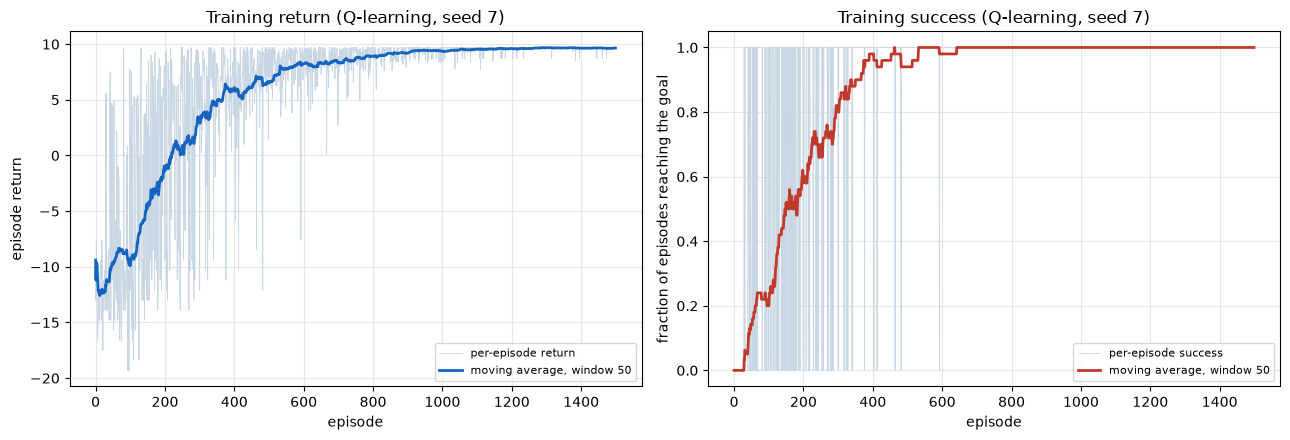

In [9]:
# --- Task 5: the training curves ---

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(returns, color="#c9d6e3", linewidth=0.6, label="per-episode return")
ax.plot(moving_average(returns, WINDOW), color="#1565c0", linewidth=2.0,
        label="moving average, window %d" % WINDOW)
ax.set_xlabel("episode")
ax.set_ylabel("episode return")
ax.set_title("Training return (Q-learning, seed %d)" % SEED)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(successes, color="#c9d6e3", linewidth=0.6, label="per-episode success")
ax.plot(moving_average(successes, WINDOW), color="#c0392b", linewidth=2.0,
        label="moving average, window %d" % WINDOW)
ax.set_xlabel("episode")
ax.set_ylabel("fraction of episodes reaching the goal")
ax.set_title("Training success (Q-learning, seed %d)" % SEED)
ax.set_ylim(-0.05, 1.05)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### The greedy evaluation

**Question: what does the learned policy actually do when exploration is
switched off?**

The evaluation is run with $\varepsilon = 0$ and **no learning updates**,
from the default start $(2,0)$. The trajectory is printed and drawn, and its
length is compared with the route identified in Task 1(d).

In [10]:
# --- Task 5: greedy evaluation from the default start ---

evaluation = greedy_rollout(Q_final)

print("Greedy evaluation (epsilon = 0, no updates, start %s)" % (START,))
print("-" * 68)
print("  trajectory :", evaluation["trajectory"])
print("  length     :", evaluation["length"], "moves")
print("  return     :", round(evaluation["return"], 4))
print("  invalid    :", evaluation["invalid"])
print("  success    :", evaluation["success"])
print("  timeout    :", evaluation["timeout"])
print()
print("  Task 1(d) predicted the shortest route is 4 moves.")
print("  The learned greedy policy uses %d moves." % evaluation["length"])
print("  Optimal?    :", evaluation["length"] == 4)
print()
print("  the map, with the greedy trajectory marked:")
for r in range(ROWS):
    line = []
    for c in range(COLS):
        ch = "#" if (r, c) in OBSTACLES else ("G" if (r, c) == GOAL
                                              else ("S" if (r, c) == START else "."))
        line.append(ch)
    print("   ", " ".join(line))
print("    step:  " + "  ".join(str(i) for i in range(len(evaluation["trajectory"]))))
print("    A  ->  " + "  ".join("(%d,%d)" % p for p in evaluation["trajectory"]))

Greedy evaluation (epsilon = 0, no updates, start (2, 0))
--------------------------------------------------------------------
  trajectory : [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
  length     : 4 moves
  return     : 9.7
  invalid    : 0
  success    : True
  timeout    : False

  Task 1(d) predicted the shortest route is 4 moves.
  The learned greedy policy uses 4 moves.
  Optimal?    : True

  the map, with the greedy trajectory marked:
    . . # . .
    . . # . .
    S . . . G
    . . # . .
    . . # . .
    step:  0  1  2  3  4
    A  ->  (2,0)  (2,1)  (2,2)  (2,3)  (2,4)


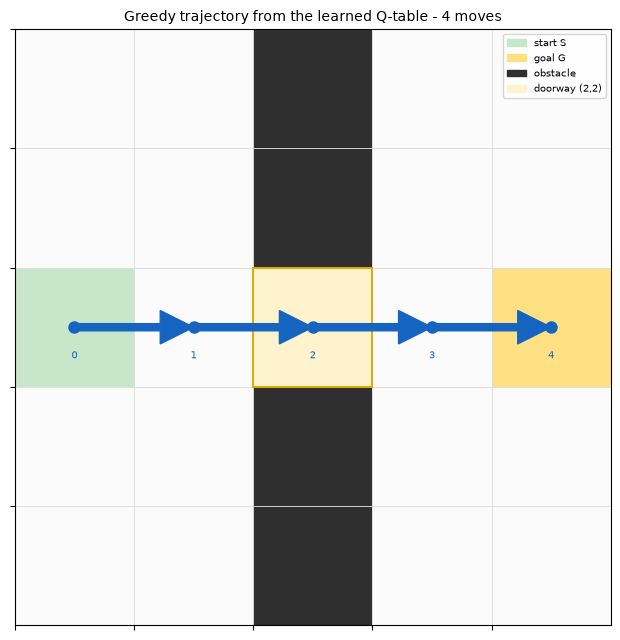

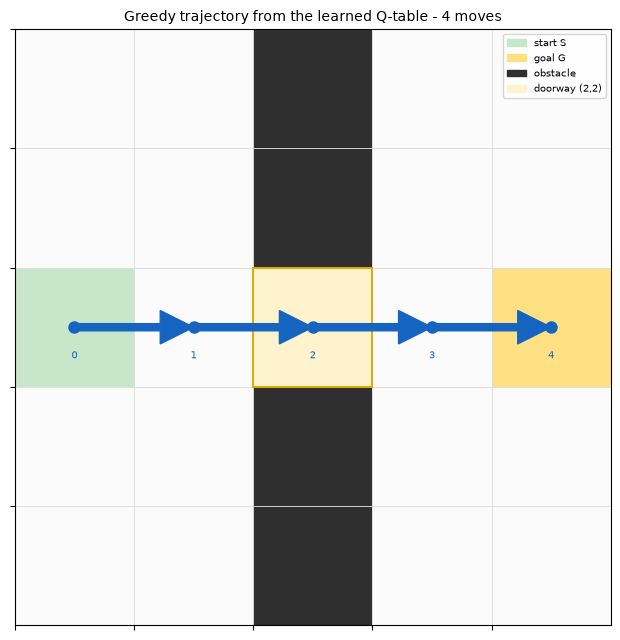

In [11]:
# --- Task 5: draw the greedy trajectory on the grid ---

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyArrow

def draw_warehouse(trajectory=None, path_a=None, path_b=None, title=""):
    """Draw the 5x5 warehouse.  path_a/path_b are trajectories to draw."""
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) in OBSTACLES:
                colour = "#2f2f2f"
            elif (r, c) == GOAL:
                colour = "#ffe082"
            elif (r, c) == START:
                colour = "#c8e6c9"
            else:
                colour = "#fbfbfb"
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=colour,
                                       edgecolor="#dddddd", linewidth=0.6))
    # the doorway
    ax.add_patch(plt.Rectangle((2, 2), 1, 1, facecolor="#fff3cd",
                               edgecolor="#e0a800", linewidth=1.4))
    for path, colour, marker in ((path_a, "#1565c0", "o"), (path_b, "#c0392b", "s")):
        if not path:
            continue
        for i, (r, c) in enumerate(path):
            ax.plot(c + 0.5, r + 0.5, marker, color=colour, markersize=8,
                    zorder=3)
            ax.text(c + 0.5, r + 0.78, str(i), ha="center", va="bottom",
                    fontsize=7, color=colour)
        for (r1, c1), (r2, c2) in zip(path[:-1], path[1:]):
            ax.add_patch(FancyArrow(c1 + 0.5, r1 + 0.5, c2 - c1, r2 - r1,
                                    width=0.06, head_width=0.28, head_length=0.28,
                                    length_includes_head=True, color=colour,
                                    zorder=2))
    ax.set_xlim(0, COLS)
    ax.set_ylim(ROWS, 0)
    ax.set_aspect("equal")
    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_title(title, fontsize=10)
    ax.legend(handles=[Patch(color="#c8e6c9", label="start S"),
                       Patch(color="#ffe082", label="goal G"),
                       Patch(color="#2f2f2f", label="obstacle"),
                       Patch(color="#fff3cd", label="doorway (2,2)")],
              loc="upper right", fontsize=7)
    plt.tight_layout()
    plt.show()
    return fig


draw_warehouse(path_a=evaluation["trajectory"],
                title="Greedy trajectory from the learned Q-table - %d moves"
                      % evaluation["length"])

### Comparison with a uniformly random policy

**Question: how much of the performance is due to learning?**

The random policy is given the **same** map, start, rewards and 40-step
cutoff, and is run for **100 episodes**. It picks uniformly from the 5
actions at every step.

For the random policy the lab asks for the **success fraction**, the
**timeout fraction** and the **mean number of steps among the successful
runs**. For the deterministic greedy policy there is only a single rollout,
so its outcome, path length and invalid-move count are reported as single
numbers.

A note on statistics: the greedy policy is deterministic, so repeating its
rollout from the same start produces *the same* trajectory every time. It is
one trial, not 100. The random policy, by contrast, genuinely produces 100
independent trials.

In [12]:
# --- Task 5: random policy vs the learned greedy policy ---

def random_policy(episodes=100, seed=SEED, max_steps=MAX_STEPS):
    """Run a uniformly random policy. Same map, start, rewards and cutoff."""
    rng = np.random.default_rng(seed)
    env = WarehouseEnv(max_steps=max_steps)
    successes, timeouts = 0, 0
    steps_to_goal, invalid_total = [], 0
    for _ in range(episodes):
        pos = env.reset(START)
        invalid = 0
        for s in range(max_steps):
            action = int(rng.integers(len(ACTION_NAMES)))
            nxt, reward, term, trunc, inv = env.step(action)
            invalid += inv
            pos = nxt
            if term:
                successes += 1
                steps_to_goal.append(s + 1)
                break
        else:
            timeouts += 1
        invalid_total += invalid
    return {"episodes": episodes, "successes": successes, "timeouts": timeouts,
            "success_fraction": successes / episodes,
            "timeout_fraction": timeouts / episodes,
            "mean_steps_success": float(np.mean(steps_to_goal)) if steps_to_goal else None,
            "min_steps_success": int(min(steps_to_goal)) if steps_to_goal else None,
            "max_steps_success": int(max(steps_to_goal)) if steps_to_goal else None,
            "invalid_total": invalid_total,
            "invalid_per_episode": invalid_total / episodes}


random_stats = random_policy(episodes=100, seed=SEED)

print("Random policy vs greedy Q-policy (100 episodes, seed %d)" % SEED)
print("-" * 78)
print("%-34s %-20s %-20s" % ("Measure", "Random policy", "Greedy Q-policy"))
print("-" * 78)
print("%-34s %-20s %-20s" % ("Runs", random_stats["episodes"], 1))
print("%-34s %-20s %-20s" % ("Goal reached",
                             "%d / 100" % random_stats["successes"],
                             "yes" if evaluation["success"] else "no"))
print("%-34s %-20s %-20s" % ("Success fraction",
                             round(random_stats["success_fraction"], 2),
                             "1.00" if evaluation["success"] else "0.00"))
print("%-34s %-20s %-20s" % ("Timeouts",
                             "%d / 100" % random_stats["timeouts"],
                             "0" if not evaluation["timeout"] else "1"))
print("%-34s %-20s %-20s" % ("Timeout fraction",
                             round(random_stats["timeout_fraction"], 2),
                             "0.00" if not evaluation["timeout"] else "1.00"))
print("%-34s %-20s %-20s" % ("Steps to goal, if successful",
                             round(random_stats["mean_steps_success"], 2)
                             if random_stats["mean_steps_success"] else "-",
                             evaluation["length"]))
print("%-34s %-20s %-20s" % ("   shortest / longest such run",
                             "%d / %d" % (random_stats["min_steps_success"],
                                         random_stats["max_steps_success"]),
                             "-"))
print("%-34s %-20s %-20s" % ("Invalid moves (total)",
                             random_stats["invalid_total"],
                             evaluation["invalid"]))
print("%-34s %-20s %-20s" % ("Invalid moves (per episode)",
                             round(random_stats["invalid_per_episode"], 2),
                             evaluation["invalid"]))
print("-" * 78)
print("The random policy reaches the goal %d times in 100 runs, and when it does"
      % random_stats["successes"])
print("it takes %.1f moves on average - against %d for the greedy policy."
      % (random_stats["mean_steps_success"], evaluation["length"]))

Random policy vs greedy Q-policy (100 episodes, seed 7)
------------------------------------------------------------------------------
Measure                            Random policy        Greedy Q-policy     
------------------------------------------------------------------------------
Runs                               100                  1                   
Goal reached                       18 / 100             yes                 
Success fraction                   0.18                 1.00                
Timeouts                           82 / 100             0                   
Timeout fraction                   0.82                 0.00                
Steps to goal, if successful       26.94                4                   
   shortest / longest such run     8 / 40               -                   
Invalid moves (total)              986                  0                   
Invalid moves (per episode)        9.86                 0                   
----------------

### Answers

**(a) Why might the training curve remain noisy after a good route is
learned?**

Because the *training* episodes are still driven by $\varepsilon$-greedy
action selection, and $\varepsilon$ only falls to 0.05 by episode 1200 and
then stays there. Even at $\varepsilon = 0.05$ one episode in twenty takes a
completely random action, and a random action from the corridor can send the
robot into a wall for $-1$ or into a 40-step timeout worth $-4$. The learning
signal itself is noisy for a second reason: the return of an episode depends
on *when* the goal is reached, and a single unlucky detour costs several
$-0.1$ steps. A moving average over 50 episodes hides most of this, but the
curve never becomes perfectly flat.

The noise is also *legitimate information*: it shows that the policy is still
being tested, not that the agent has failed. A curve that is smooth because
the agent stopped exploring would be a worse sign, not a better one.

**(b) Does a high training return necessarily imply a good greedy policy?**

**No.** They measure different things, and three specific reasons separate
them here:

1. *The training return is an average over $\varepsilon$-greedy episodes.* It
   includes the randomness of exploration, so it is a lower bound on the
   greedy policy's performance, not a description of it.
2. *A single episode can end well by luck.* An episode that reaches the goal
   after a few random moves scores well without the policy having caused it.
3. *The return is not the policy.* The quantity that matters is the
   **greedy trajectory** — what the agent does when exploration is switched
   off. That is why the lab asks for the greedy evaluation separately, with
   $\varepsilon = 0$ and no updates.

There is a concrete failure mode behind this: an agent that always reaches
the goal by wandering backwards from it scores a high *average* return while
its greedy policy walks straight into a wall. The way to rule this out is to
look at the greedy rollout, which is what the evaluation above does.

**(c) What is the difference between the learning rate $\alpha$ and the
exploration probability $\varepsilon$?**

They act on completely different parts of the algorithm.

| | $\alpha$ (learning rate) | $\varepsilon$ (exploration probability) |
|---|---|---|
| **Acts on** | the *update* of $Q(s,a)$ | the *choice of action* |
| **Question it answers** | "how much do I trust this one sample?" | "how often do I ignore what I have learned?" |
| **Effect of $\alpha \to 0$** | updates become tiny; nothing is learned | — |
| **Effect of $\varepsilon \to 0$** | — | the agent always takes the greedy action and stops trying anything new |
| **Failure mode** | $\alpha$ too big: the table oscillates; too small: nothing is learned | $\varepsilon$ too big: mostly random; too small: the agent locks into a poor action it happened to try first |

A clean analogy: $\alpha$ is **how carefully you update your notes** after
seeing something, and $\varepsilon$ is **how often you try a different route
at all**. Both have to be right, but they are not the same knob. Note also
that $\alpha$ and $\varepsilon$ interact: a small $\alpha$ means the table
changes slowly, so it takes more exploration to discover anything at all.

### Optional investigation: what happens with no exploration at all?

**Question: does the $\varepsilon$-greedy agent only succeed because of its
exploration?**

A fresh Q-table is trained with $\varepsilon = 0$ for every episode, with
everything else unchanged. The lab's warning is important here: *do not
assume that no exploration must fail — random tie-breaking and initial values
can also affect the actions tried.*

Two variants are run, because "no exploration" can mean two different things:

- **A. $\varepsilon = 0$, random tie-breaking kept.** This is the faithful
  reading of the lab's investigation: the exploration *probability* is
  removed, the training tie-breaking rule is unchanged.
- **B. $\varepsilon = 0$, deterministic tie-breaking** (smallest action index
  wins). This removes the tie-breaking randomness as well, so the very first
  actions are forced.

Both are also run with a second seed, because the lab asks for that where
time permits.

In [13]:
# --- Task 5 optional investigation: a fresh Q-table with no exploration ---

no_explore_variants = [
    ("A: eps = 0, random ties", dict(explore=False, random_ties=True)),
    ("B: eps = 0, fixed ties", dict(explore=False, random_ties=False)),
]

print("Optional investigation - training without epsilon-greedy exploration")
print("-" * 88)
print("%-28s %-8s %-12s %-12s %-26s"
      % ("variant", "seed", "train succ.", "greedy len", "greedy trajectory"))
print("-" * 88)

explore_results = []
for label, kwargs in no_explore_variants:
    for seed in (SEED, 42):
        Q_no, log_no = train(seed=seed, episodes=1500, **kwargs)
        ev_no = greedy_rollout(Q_no)
        rate = np.mean([l["success"] for l in log_no])
        print("%-28s %-8d %-12.3f %-12s %-26s"
              % (label, seed, rate, ev_no["length"], str(ev_no["trajectory"])))
        explore_results.append((label, seed, rate, ev_no))

print("-" * 88)
print("For comparison, the epsilon-greedy run (seed %d):" % SEED)
print("  train success rate %.3f, greedy length %d, trajectory %s"
      % (successes[-50:].mean(), evaluation["length"], evaluation["trajectory"]))
print()
print("Both no-exploration variants reach the goal. The reasons are worth")
print("stating precisely:")
print()
print("  Variant A keeps the random tie-breaking rule, and with a ZERO")
print("  initial table every action in every state starts out tied at 0.")
print("  So the 'greedy' action is chosen uniformly at random until the")
print("  values start to differ - the agent explores by accident.")
print()
print("  Variant B uses a fixed tie-break, so the agent always tries the")
print("  lowest-numbered action first. That is not random, but it is not")
print("  stationary either: each action gets tried once, its value turns")
print("  negative, and the next-lowest action becomes the argmax. The")
print("  agent sweeps its way through the action set and learns.")
print()
print("The lesson is the one the lab states: on a map this small, with a")
print("zero-initialised table and a sensible tie-breaking rule, 'no")
print("exploration' still explores. The failure mode the lab is warning")
print("about is real in general, but it did not happen here, and the")
print("reason is understood rather than lucky.")

Optional investigation - training without epsilon-greedy exploration
----------------------------------------------------------------------------------------
variant                      seed     train succ.  greedy len   greedy trajectory         
----------------------------------------------------------------------------------------
A: eps = 0, random ties      7        0.998        4            [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]


A: eps = 0, random ties      42       0.997        4            [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
B: eps = 0, fixed ties       7        0.998        4            [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
B: eps = 0, fixed ties       42       0.998        4            [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
----------------------------------------------------------------------------------------
For comparison, the epsilon-greedy run (seed 7):
  train success rate 1.000, greedy length 4, trajectory [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]

Both no-exploration variants reach the goal. The reasons are worth
stating precisely:

  Variant A keeps the random tie-breaking rule, and with a ZERO
  initial table every action in every state starts out tied at 0.
  So the 'greedy' action is chosen uniformly at random until the
  values start to differ - the agent explores by accident.

  Variant B uses a fixed tie-break, so the agent always tries the
  lowest-numbered action first. That is n

## Part II: Replace the Table with a Neural Network

**Question: what actually changes when the Q-table becomes a network, and
what must stay exactly the same?**

| | Stays the same | Changes |
|---|---|---|
| **Environment** | The map, obstacles, start, goal, the three reward rules, the 40-step cutoff, and the termination/truncation distinction | Nothing |
| **Maths** | $\gamma = 0.95$, the TD target $y = r + \gamma(1-d)\max_{a'}Q(s',a')$, the MSE loss, $\varepsilon$-greedy action selection | The representation of $s$ and the way $Q$ is computed |
| **Representation** | — | Cell $(r,c)$ becomes a **length-25 one-hot vector** with a `1` at index $5r+c$ |
| **Function approximator** | — | A $25 \to 64 \to 64 \to 5$ network with ReLU hidden layers and **linear** outputs |
| **Memory** | — | A **replay buffer** of 20,000 transitions, sampled in random batches of 64 |
| **Second network** | — | A **target network**, a frozen copy used to compute the targets, refreshed every 250 optimiser updates |

Three points in the table deserve emphasis.

**The outputs are Q-values, not probabilities.** There is no softmax and no
cross-entropy. The last layer is linear because the Bellman target is a
number, not a distribution. (A softmax here would be a category error: the
five outputs are five *different* action values, not five classes competing
for one probability mass.)

**The one-hot input is a lookup table in disguise.** The Q-table would hold
$25 \times 5 = 125$ numbers (105 of them for reachable states); the network
replaces them with
$25\cdot64 + 64 + 64\cdot64 + 64 + 64\cdot5 + 5 = 6149$ weights that are
shared across states and generalised by the hidden layers. The one-hot
encoding still means the network has never seen a state it was not trained on,
so the generalisation is only across *similar* states.

**The target network is a copy of the online network.** It exists so that the
regression target does not move while the optimiser is chasing it. Without
it the target would shift every single step and the learning would be
unstable.

### The prompt

```text
Extend my validated single-robot program to use DQN in PyTorch. Keep the
environment, rewards, start, goal, and discount unchanged.

Use the specified one-hot input and two 64-unit ReLU hidden layers. Output
five Q-values without softmax. Use epsilon-greedy action selection, a replay
buffer, and a target network.

Use a replay capacity of 20,000 transitions and random batches of 64.
Initialize the target network from the online network. Collect 500 steps
before learning, perform one optimizer update every four environment steps,
and copy the online weights to the target every 250 optimizer updates.

Use Adam with learning rate 0.001 and mean squared TD error. Compute detached
targets with torch.no_grad(). Use a reward-only target for termination and
bootstrap at truncation.

Train for 12,000 environment steps with seed 7. Decrease epsilon linearly
from 1 to 0.05 over the first 80 percent of training. Keep training and
greedy evaluation separate. Explain where the recorded action is selected
when computing the loss.
```

**Where the recorded action is selected when computing the loss.** The
network outputs five numbers, one per action. The target $y_i$ is a single
number for the *transition*, but the prediction must be the value of the
action that was actually taken. That is done with

```python
pred = q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
```

`gather` picks, for each row of the batch, the output at the index of the
recorded action. Using `max(dim=1)` here instead would compute the value of
the *best* action in the next state for the prediction as well — a different
quantity, and the reason a DQN can look like it is learning while actually
evaluating a different action.

In [14]:
# --- the DQN implementation ---

import torch
import torch.nn as nn

N_STATES = ROWS * COLS
N_ACTIONS = len(ACTION_NAMES)
N_INPUTS = N_STATES        # 25 one-hot inputs
HIDDEN = 64


def one_hot(pos):
    """Cell (r, c) -> length-25 one-hot vector with a 1 at index 5r + c."""
    v = np.zeros(N_STATES, dtype=np.float32)
    v[cell_index(pos)] = 1.0
    return v


class QNetwork(nn.Module):
    """25 inputs -> 64 ReLU -> 64 ReLU -> 5 linear outputs.

    The output layer is linear on purpose: these are Q-values, not
    probabilities, so there is no softmax.
    """

    def __init__(self, n_inputs=N_INPUTS, n_outputs=N_ACTIONS, hidden=HIDDEN):
        super().__init__()
        self.fc1 = nn.Linear(n_inputs, hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.fc3 = nn.Linear(hidden, n_outputs)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)


class ReplayBuffer:
    """A fixed-capacity store of transitions, sampled uniformly at random."""

    def __init__(self, capacity=20000):
        self.capacity = capacity
        self.data = []
        self.index = 0

    def push(self, transition):
        if len(self.data) < self.capacity:
            self.data.append(transition)
        else:
            self.data[self.index] = transition          # overwrite the oldest
        self.index = (self.index + 1) % self.capacity

    def sample(self, batch_size, rng):
        picks = rng.choice(len(self.data), size=batch_size, replace=False)
        return [self.data[i] for i in picks]

    def __len__(self):
        return len(self.data)


def dqn_loss(q_net, target_net, states, actions, rewards, next_states,
             dones, gamma=GAMMA):
    """The DQN loss, and the pieces it is made of.

    dones is 1.0 for TRUE TERMINATION and 0.0 otherwise.  A truncated
    transition therefore keeps its continuation term - the task was cut
    short by the collection budget, not finished.

    Returns (loss, targets, predictions).
    """
    with torch.no_grad():                       # detached targets
        next_q = target_net(next_states).max(dim=1).values
        y = rewards + gamma * (1.0 - dones) * next_q
    # the prediction is the value of the RECORDED action, not the best one
    pred = q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    loss = ((pred - y) ** 2).mean()
    return loss, y, pred


class DQNAgent:
    """The DQN agent: online network, target network, replay buffer, optimiser."""

    def __init__(self, n_inputs=N_INPUTS, n_outputs=N_ACTIONS, seed=7,
                 gamma=GAMMA, lr=0.001, capacity=20000, batch_size=64,
                 warmup=500, train_every=4, target_sync=250,
                 eps_end=0.05, eps_decay_fraction=0.8):
        torch.manual_seed(seed)
        self.n_outputs = n_outputs
        self.gamma = gamma
        self.batch_size = batch_size
        self.warmup = warmup
        self.train_every = train_every
        self.target_sync = target_sync
        self.eps_end = eps_end
        self.eps_decay_fraction = eps_decay_fraction

        self.q_net = QNetwork(n_inputs, n_outputs)
        self.target_net = QNetwork(n_inputs, n_outputs)
        self.target_net.load_state_dict(self.q_net.state_dict())   # init from online
        for p in self.target_net.parameters():
            p.requires_grad_(False)
        self.optimiser = torch.optim.Adam(self.q_net.parameters(), lr=lr)
        self.buffer = ReplayBuffer(capacity)
        self.rng = np.random.default_rng(seed)
        self.updates = 0

    def epsilon(self, step, total_steps):
        """Linear from 1.0 to eps_end over the first eps_decay_fraction."""
        frac = min(1.0, step / (self.eps_decay_fraction * total_steps))
        return 1.0 + (self.eps_end - 1.0) * frac

    def act(self, state_vector, epsilon):
        """epsilon-greedy over the network's outputs."""
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_outputs))
        with torch.no_grad():
            q = self.q_net(torch.from_numpy(state_vector).unsqueeze(0))
        return int(torch.argmax(q, dim=1).item())

    def remember(self, state, action, reward, next_state, terminated):
        """Store a transition. `terminated` is the TRUE TERMINATION flag."""
        self.buffer.push((state, action, reward, next_state, float(terminated)))

    def learn(self):
        """One optimiser update. Returns the loss, or None if not ready."""
        if len(self.buffer) < self.batch_size:
            return None
        batch = self.buffer.sample(self.batch_size, self.rng)
        states = torch.from_numpy(np.stack([b[0] for b in batch]))
        actions = torch.tensor([b[1] for b in batch], dtype=torch.long)
        rewards = torch.tensor([b[2] for b in batch], dtype=torch.float32)
        next_states = torch.from_numpy(np.stack([b[3] for b in batch]))
        dones = torch.tensor([b[4] for b in batch], dtype=torch.float32)

        loss, _y, _pred = dqn_loss(self.q_net, self.target_net, states, actions,
                                   rewards, next_states, dones, self.gamma)
        self.optimiser.zero_grad()
        loss.backward()
        self.optimiser.step()
        self.updates += 1
        return loss.item()

    def sync_target(self):
        """Copy the online weights into the target network."""
        self.target_net.load_state_dict(self.q_net.state_dict())


print("network:")
print(QNetwork())
print()
print("parameters in the network :", sum(p.numel() for p in QNetwork().parameters()))
print("parameters in a Q-table   :", N_STATES * N_ACTIONS)
print("replay buffer capacity    : 20,000 transitions")
print("batch size                : 64")
print("warm-up before learning   : 500 environment steps")
print("optimiser update every    : 4 environment steps")
print("target sync every         : 250 optimiser updates")

network:
QNetwork(
  (fc1): Linear(in_features=25, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=5, bias=True)
)

parameters in the network : 6149
parameters in a Q-table   : 125
replay buffer capacity    : 20,000 transitions
batch size                : 64
warm-up before learning   : 500 environment steps
optimiser update every    : 4 environment steps
target sync every         : 250 optimiser updates


### Testing the loss before training

**Question: does the DQN compute the target it is supposed to?**

The lab asks for the loss to be tested on a batch whose targets can be
calculated by hand. The three cases are the same three cases used for the
tabular update, because they are the same mathematics:

| Case | $r$ | max target-network next value | Expected target $y$ |
|---|---|---|---|
| non-terminal | 1 | 2 | $1 + 0.95 \cdot 2 = 2.9$ |
| **terminal** | 5 | 2 | $5$ (no continuation term) |
| truncated | 1 | 2 | $1 + 0.95 \cdot 2 = 2.9$ (still bootstraps) |

To make the targets exactly calculable, the two networks are **constructed
by hand** rather than randomly:

- the **target** network gets a zero output layer and a constant bias of 2, so
  it outputs 2 for every action and every state — the maximum next-state
  value is exactly 2;
- the **online** network gets a zero output layer and the bias
  $[0.1, 0.2, 0.3, 0.4, 0.5]$, so $Q_\theta(s,a)$ is exactly the bias of
  the recorded action.

The recorded actions are chosen to differ from each other, so that using the
recorded action can be distinguished from using the best action.

In [15]:
# --- the hand-constructed loss test ---

# target network: every output is exactly 2 -> max next-state value is 2
target_controlled = QNetwork()
with torch.no_grad():
    target_controlled.fc3.weight.zero_()
    target_controlled.fc3.bias.copy_(torch.tensor([2.0, 2.0, 2.0, 2.0, 2.0]))

# online network: Q(s, a) == the bias of action a
online_controlled = QNetwork()
with torch.no_grad():
    online_controlled.fc3.weight.zero_()
    online_controlled.fc3.bias.copy_(torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5]))

# a batch of three transitions:  s, a, r, s', terminated, truncated
BATCH = [
    ((2, 0), 2, 1.0, (2, 1), False, False),   # non-terminal
    ((2, 1), 0, 5.0, (2, 4), True,  False),   # terminal
    ((2, 2), 3, 1.0, (2, 3), False, True),    # truncated
]

states = torch.from_numpy(np.stack([one_hot(b[0]) for b in BATCH]))
actions = torch.tensor([b[1] for b in BATCH], dtype=torch.long)
rewards = torch.tensor([b[2] for b in BATCH], dtype=torch.float32)
next_states = torch.from_numpy(np.stack([one_hot(b[3]) for b in BATCH]))
dones = torch.tensor([1.0 if b[4] else 0.0 for b in BATCH], dtype=torch.float32)

loss, y, pred = dqn_loss(online_controlled, target_controlled, states,
                         actions, rewards, next_states, dones)

print("DQN loss test on a hand-constructed batch")
print("-" * 88)
print("%-16s %-8s %-10s %-14s %-12s %-12s"
      % ("case", "r", "max next Q", "expected y", "expected pred", "expected loss"))
print("-" * 88)

expectations = [
    ("non-terminal", 1.0, 2.0, 2.9, 0.3, (0.3 - 2.9) ** 2),
    ("terminal",     5.0, 2.0, 5.0, 0.1, (0.1 - 5.0) ** 2),
    ("truncated",    1.0, 2.0, 2.9, 0.4, (0.4 - 2.9) ** 2),
]
for i, (label, r, mx, want_y, want_pred, sq) in enumerate(expectations):
    print("%-16s %-8s %-10s %-14s %-12s %-12s"
          % (label, r, mx, want_y, want_pred, round(sq, 4)))
print("-" * 88)
print("targets computed by the program :", [round(float(v), 4) for v in y.detach().numpy()])
print("targets computed by hand        :", [e[3] for e in expectations])
print("predictions (recorded action)   :", [round(float(v), 4) for v in pred.detach().numpy()])
print("predictions expected            :", [e[4] for e in expectations])
expected_loss = float(np.mean([e[5] for e in expectations]))
print("loss computed by the program    :", round(loss.item(), 6))
print("loss computed by hand           :", round(expected_loss, 6))
print()
assert np.allclose(y.numpy(), [e[3] for e in expectations]), "targets"
assert np.allclose(pred.detach().numpy(), [e[4] for e in expectations]), "predictions"
assert abs(loss.item() - expected_loss) < 1e-6, "loss"
print("[PASS] the targets are 2.9, 5.0, 2.9 - the terminal case drops the")
print("       continuation term and the truncated case keeps it.")
print("[PASS] the predictions are the values of the RECORDED actions.")
print("[PASS] the loss is the mean squared error of the three targets.")
print()

# --- does the loss really use the RECORDED action? ---
with torch.no_grad():
    wrong_actions = torch.argmax(online_controlled(states), dim=1)
    wrong_pred = online_controlled(states).gather(1, wrong_actions.unsqueeze(1)).squeeze(1)
wrong_loss = ((wrong_pred - y) ** 2).mean()
print("If the loss had used the BEST action instead of the recorded one:")
print("  actions used :", wrong_actions.tolist())
print("  predictions  :", [round(float(v), 4) for v in wrong_pred.numpy()])
print("  loss         :", round(wrong_loss.item(), 6),
      " instead of", round(loss.item(), 6))
print("  -> a different number, so the two are genuinely different code paths.")
print()

# --- do gradients flow into the target network? ---
target_grads = [p.grad for p in target_controlled.parameters()]
loss.backward()
after = [p.grad for p in target_controlled.parameters()]
print("Gradient check on the target network")
print("-" * 88)
print("  target parameters with .grad set :",
      sum(1 for g in after if g is not None), "of", len(after))
print("  online  parameters with .grad set :",
      sum(1 for p in online_controlled.parameters() if p.grad is not None),
      "of", len(list(online_controlled.parameters())))
assert all(g is None for g in after), "gradients leaked into the target network"
assert any(p.grad is not None for p in online_controlled.parameters())
print("[PASS] no gradient reaches the target network (its targets were built")
print("       under torch.no_grad()), and the online network does get one.")

DQN loss test on a hand-constructed batch
----------------------------------------------------------------------------------------
case             r        max next Q expected y     expected pred expected loss
----------------------------------------------------------------------------------------
non-terminal     1.0      2.0        2.9            0.3          6.76        
terminal         5.0      2.0        5.0            0.1          24.01       
truncated        1.0      2.0        2.9            0.4          6.25        
----------------------------------------------------------------------------------------
targets computed by the program : [2.9, 5.0, 2.9]
targets computed by hand        : [2.9, 5.0, 2.9]
predictions (recorded action)   : [0.3, 0.1, 0.4]
predictions expected            : [0.3, 0.1, 0.4]
loss computed by the program    : 12.34
loss computed by hand           : 12.34

[PASS] the targets are 2.9, 5.0, 2.9 - the terminal case drops the
       continuation term and 

### Training the DQN

**Question: can the network learn the same route the table learned?**

12,000 environment steps, seed 7, $\varepsilon$ decreasing linearly from 1 to
0.05 over the first 80 % of training (the first 9600 steps). 500 warm-up
steps are collected before the first update, one optimiser update is made
every 4 environment steps, and the target network is refreshed every 250
optimiser updates.

The learning rate ($\alpha = 0.001$, Adam) and the exploration probability
$\varepsilon$ play the same two distinct roles they played in Part I: $\alpha$
governs how much each batch moves the weights, $\varepsilon$ governs how
often the agent ignores what it has learned.

In [16]:
# --- DQN training on the single-robot environment ---

def train_dqn_single(total_steps=12000, seed=SEED):
    agent = DQNAgent(n_inputs=N_INPUTS, n_outputs=N_ACTIONS, seed=seed)
    env = WarehouseEnv()
    pos = env.reset()

    losses = []
    episode_returns = []
    episode_steps = []
    episode_invalid = []
    ep_return, ep_len, ep_invalid = 0.0, 0, 0

    for step in range(total_steps):
        epsilon = agent.epsilon(step, total_steps)
        state = one_hot(pos)
        action = agent.act(state, epsilon)
        nxt, reward, terminated, truncated, invalid = env.step(action)

        # done = TERMINATION only; a truncated transition still bootstraps
        agent.remember(state, action, reward, one_hot(nxt), terminated)

        ep_return += reward
        ep_len += 1
        ep_invalid += invalid
        if terminated or truncated:
            episode_returns.append(ep_return)
            episode_steps.append(ep_len)
            episode_invalid.append(ep_invalid)
            pos = env.reset()
            ep_return, ep_len, ep_invalid = 0.0, 0, 0
        else:
            pos = nxt

        if step >= agent.warmup and (step - agent.warmup) % agent.train_every == 0:
            value = agent.learn()
            if value is not None:
                losses.append((step, value))
                if agent.updates % agent.target_sync == 0:
                    agent.sync_target()

    return agent, losses, episode_returns, episode_steps, episode_invalid


dqn_agent, dqn_losses, dqn_returns, dqn_ep_steps, dqn_ep_invalid = \
    train_dqn_single(total_steps=12000, seed=SEED)

loss_values = np.array([v for _s, v in dqn_losses])
print("DQN training summary (seed %d, %d environment steps)" % (SEED, 12000))
print("-" * 74)
print("  optimiser updates made   :", dqn_agent.updates)
print("  target network syncs     :", dqn_agent.updates // dqn_agent.target_sync)
print("  transitions in the buffer:", len(dqn_agent.buffer))
print("  mean loss, first 100     : %.5f" % loss_values[:100].mean())
print("  mean loss, last 100      : %.5f" % loss_values[-100:].mean())
print("  episodes completed       :", len(dqn_returns))
if dqn_returns:
    print("  mean episode return      : %.3f" % np.mean(dqn_returns))
    print("  final episode return     : %.3f" % dqn_returns[-1])
    print("  episodes reaching goal   : %d of %d"
          % (sum(1 for r in dqn_returns if r > 5), len(dqn_returns)))

DQN training summary (seed 7, 12000 environment steps)
--------------------------------------------------------------------------
  optimiser updates made   : 2875
  target network syncs     : 11
  transitions in the buffer: 12000
  mean loss, first 100     : 0.40288
  mean loss, last 100      : 0.00772
  episodes completed       : 1393
  mean episode return      : 7.873
  final episode return     : 9.700
  episodes reaching goal   : 1273 of 1393


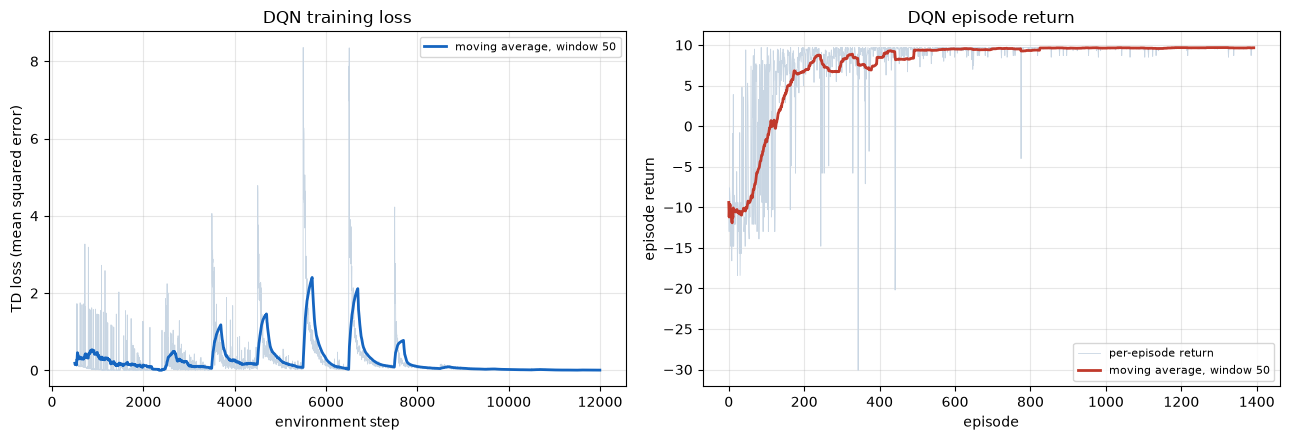

In [17]:
# --- the DQN training curve ---

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
steps_axis = np.array([s for s, _v in dqn_losses])
ax.plot(steps_axis, loss_values, color="#c9d6e3", linewidth=0.6)
if len(loss_values) >= WINDOW:
    ax.plot(steps_axis, moving_average(loss_values, WINDOW), color="#1565c0",
            linewidth=2.0, label="moving average, window %d" % WINDOW)
ax.set_xlabel("environment step")
ax.set_ylabel("TD loss (mean squared error)")
ax.set_title("DQN training loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
if dqn_returns:
    ax.plot(dqn_returns, color="#c9d6e3", linewidth=0.6, label="per-episode return")
    ax.plot(moving_average(dqn_returns, WINDOW), color="#c0392b", linewidth=2.0,
            label="moving average, window %d" % WINDOW)
ax.set_xlabel("episode")
ax.set_ylabel("episode return")
ax.set_title("DQN episode return")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Evaluating the DQN and comparing it with the Q-table

**Question: does the network find the same route as the table?**

The DQN is evaluated exactly like the tabular agent: $\varepsilon = 0$, no
learning, greedy action selection, from the default start.

In [18]:
# --- DQN greedy evaluation ---

def dqn_greedy_rollout(agent, start=START, max_steps=MAX_STEPS):
    """Greedy evaluation with learning disabled."""
    env = WarehouseEnv(max_steps=max_steps)
    pos = env.reset(start)
    trajectory = [pos]
    total, invalid, steps = 0.0, 0, 0
    outcome = "timeout"
    while True:
        action = agent.act(one_hot(pos), 0.0)
        nxt, reward, terminated, truncated, inv = env.step(action)
        total += reward
        invalid += inv
        pos = nxt
        trajectory.append(pos)
        steps += 1
        if terminated:
            outcome = "goal"
            break
        if truncated:
            outcome = "timeout"
            break
    return {"trajectory": trajectory, "length": steps, "return": total,
            "invalid": invalid, "outcome": outcome,
            "success": outcome == "goal", "timeout": outcome == "timeout"}


dqn_eval = dqn_greedy_rollout(dqn_agent)

print("DQN greedy evaluation (epsilon = 0, no updates)")
print("-" * 74)
print("  trajectory :", dqn_eval["trajectory"])
print("  length     :", dqn_eval["length"], "moves")
print("  return     :", round(dqn_eval["return"], 4))
print("  invalid    :", dqn_eval["invalid"])
print("  outcome    :", dqn_eval["outcome"])
print()
print("Q-table agent, for comparison")
print("-" * 74)
print("  trajectory :", evaluation["trajectory"])
print("  length     :", evaluation["length"], "moves")
print("  return     :", round(evaluation["return"], 4))
print("  invalid    :", evaluation["invalid"])
print()
print("  same route?    ", dqn_eval["trajectory"] == evaluation["trajectory"])
print("  same length?   ", dqn_eval["length"] == evaluation["length"])
print("  optimal (4)?   ", dqn_eval["length"] == 4)

DQN greedy evaluation (epsilon = 0, no updates)
--------------------------------------------------------------------------
  trajectory : [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
  length     : 4 moves
  return     : 9.7
  invalid    : 0
  outcome    : goal

Q-table agent, for comparison
--------------------------------------------------------------------------
  trajectory : [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
  length     : 4 moves
  return     : 9.7
  invalid    : 0

  same route?     True
  same length?    True
  optimal (4)?    True


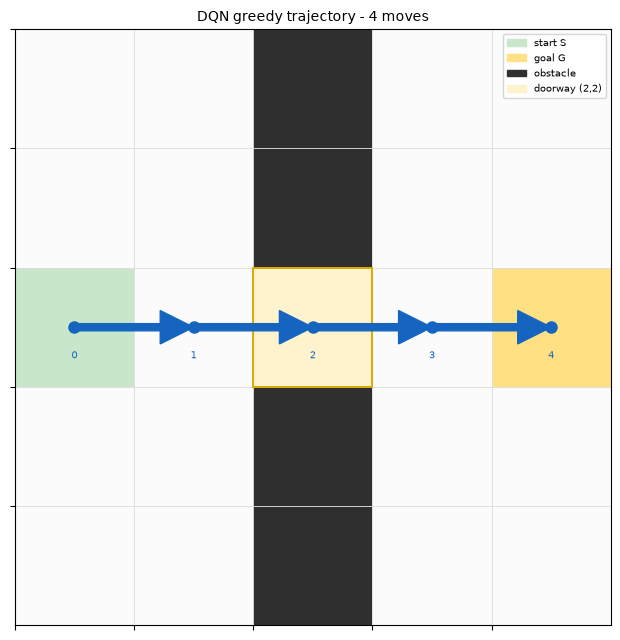

Q-values predicted by the DQN network
--------------------------------------------------------------------------
cell         Up       Down     Left     Right    Wait       greedy action
--------------------------------------------------------------------------
(2, 0)       7.068    7.058    6.758    8.364    7.692      Right
(2, 1)       7.701    7.744    7.746    8.859    8.381      Right
(2, 2)       7.986    8.019    8.224    9.378    8.842      Right
(2, 3)       8.768    8.743    8.835    9.997    9.447      Right
(0, 0)       5.724    7.024    5.647    7.136    6.563      Right
(1, 1)       7.108    8.398    7.002    7.040    7.616      Down
--------------------------------------------------------------------------
The network has learned that Right is the best action all along the
corridor, and that Up/Down/Left are worse - including at (2,0), where
Left would walk into the boundary.


In [19]:
# --- draw the DQN trajectory ---

draw_warehouse(path_a=dqn_eval["trajectory"],
                title="DQN greedy trajectory - %d moves" % dqn_eval["length"])

# --- what did the network actually learn? show the Q-values it predicts ---

print("Q-values predicted by the DQN network")
print("-" * 74)
print("%-12s %-8s %-8s %-8s %-8s %-8s   %s"
      % ("cell", "Up", "Down", "Left", "Right", "Wait", "greedy action"))
print("-" * 74)
for cell in [(2, 0), (2, 1), (2, 2), (2, 3), (0, 0), (1, 1)]:
    with torch.no_grad():
        q = dqn_agent.q_net(torch.from_numpy(one_hot(cell)).unsqueeze(0))[0]
    q = q.numpy()
    best = int(np.argmax(q))
    print("%-12s %-8.3f %-8.3f %-8.3f %-8.3f %-8.3f   %s"
          % (str(cell), q[0], q[1], q[2], q[3], q[4], ACTION_NAMES[best]))
print("-" * 74)
print("The network has learned that Right is the best action all along the")
print("corridor, and that Up/Down/Left are worse - including at (2,0), where")
print("Left would walk into the boundary.")

### Where each DQN concept lives in the code

| Concept | Where it is |
|---|---|
| **Replay buffer** | `class ReplayBuffer` — a fixed-capacity store (`push`, `sample`) wrapped around a list with a moving write index. |
| **Batch sampling** | `ReplayBuffer.sample(batch_size, rng)` — uniform random indices, no replacement; called from `DQNAgent.learn()`. |
| **State representation** | `one_hot(pos)` — length-25 vector with a `1` at index `5r+c`. |
| **Q-network** | `class QNetwork` — `25 -> 64 -> 64 -> 5`, ReLU on the two hidden layers, **linear** output layer. |
| **Target network** | `DQNAgent.target_net` — a second `QNetwork` initialised from the online one and refreshed by `sync_target()`. |
| **TD target** | `dqn_loss()`: `y = rewards + gamma * (1.0 - dones) * next_q`, computed under `torch.no_grad()`. |
| **Recorded action** | `dqn_loss()`: `pred = q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)`. |
| **Loss** | `dqn_loss()`: `((pred - y) ** 2).mean()`. |
| **Optimiser step** | `DQNAgent.learn()`: `optimiser.zero_grad()`, `loss.backward()`, `optimiser.step()`. |
| **Target synchronisation** | `DQNAgent.sync_target()`, called every 250 optimiser updates inside the training loop. |
| **Epsilon-greedy** | `DQNAgent.act(state_vector, epsilon)`, with the schedule in `DQNAgent.epsilon(step, total_steps)`. |
| **Termination vs truncation** | `agent.remember(..., terminated)` — only *true termination* sets `dones = 1`. A truncated transition keeps its continuation term. |
| **Train vs evaluate** | `train_dqn_single()` explores and learns; `dqn_greedy_rollout()` uses $\varepsilon = 0$ and never calls `learn()`. |

### Is the network better than the table?

**No — and the lab says so explicitly.** A 5×5 grid with 21 reachable states
has 105 reachable state–action pairs, which a table represents exactly and
inexpensively. The network replaces 125 table entries with 6149 parameters,
needs 12,000 environment steps instead of a few hundred, and gets the same
route.

The point of Part II is not that DQN wins. It is to make the machinery
visible: what a table stores, what a network stores instead, why the target
network has to be a separate copy, and why the loss must use the *recorded*
action. The lab also warns that the training budgets differ, so these two
runs do **not** establish which method is more sample-efficient — the DQN
used 12,000 environment steps and the table used 1500 episodes of up to 40
steps each.

## Part III: Two Robots and Collision Avoidance

**Question: how does the design change when a second robot is added, and
can the agent learn to avoid collisions?**

| Robot | Start | Goal |
|---|---|---|
| A | $(2,0)$ | $(2,4)$ |
| B | $(2,4)$ | $(2,0)$ |

The two robots have **swapped** goals. A must travel right through the
doorway, B must travel left through the same doorway, and each one's goal is
the other one's start. A robot that reaches its own goal stays there and
keeps occupying that cell.

### Designing the controller

**(a) Why is observing only A's position insufficient?**

Because the *reward* and the *legality* of the moves depend on where B is.

- Whether a joint move is legal depends on B: two robots that end in the
  same cell have collided, and two robots that exchange cells have swapped.
- Whether a move is *worth* making depends on B: entering a cell B is
  standing in is worth $-10$, not $-0.1$.
- The joint action is a pair $(a_A, a_B)$, and the value of choosing
  $a_A = \mathrm{Right}$ depends on what $a_B$ does in the same step.

Formally, the Part I state was $(r,c)$ and it was sufficient because the
map and the goal were fixed constants. Adding a second robot makes the
world itself state-dependent: the same pair of positions can lead to
different outcomes depending on how the two robots move. The state has to
grow, exactly as Part 1(b) predicted.

**(b) How will both positions be represented?**

The state is the **ordered pair** $(p_A, p_B)$ of the two robots' cells.
Each position is encoded as a length-25 one-hot vector (a `1` at index
$5r+c$), and the two are **concatenated** into a single **length-50**
input vector:

$$
\text{input} = [\text{onehot}(p_A) \;\|\; \text{onehot}(p_B)] \in \mathbb{R}^{50}
$$

So the network has **50 inputs**. The ordering matters: the network must
be able to tell which half is A and which half is B, and the reward rule
treats them symmetrically only because their goals are swapped.

**(c) How many joint actions are there?**

Each robot has 5 actions, and the two are chosen **simultaneously**, so

$$
\lvert A_{\text{joint}} \rvert = 5 \times 5 = 5^2 = \mathbf{25}.
$$

They are encoded as a single integer $j = 5a_A + a_B$ and decoded with
$a_A, a_B = \operatorname{divmod}(j, 5)$. The network therefore has **25
linear outputs**.

This is a big jump from the single-robot case: the action space grew by a
factor of 5 while the state space grew by a factor of 21. It is also the
first place where the *simultaneity* of the moves has to be encoded — the
network must learn a joint behaviour, not two independent behaviours.

**(d) One possible collision-free route for both robots**

The doorway at $(2,2)$ is a single cell, so the two robots must pass
through it at **different times**, and neither may enter the cell the other
is occupying. B also has to end up at $(2,0)$, which is A's *start*, so A
has to get out of the way of B's goal cell as well.

One route (each row is one simultaneous joint step):

| step | A's action | A at | B's action | B at | note |
|---|---|---|---|---|---|
| 0 | — | $(2,0)$ | — | $(2,4)$ | start |
| 1 | Up | $(1,0)$ | Left | $(2,3)$ | A moves aside, B advances |
| 2 | Wait | $(1,0)$ | Left | $(2,2)$ | B enters the doorway alone |
| 3 | Wait | $(1,0)$ | Left | $(2,1)$ | B clears the doorway |
| 4 | Wait | $(1,0)$ | Left | $(2,0)$ | **B has arrived** (and stays) |
| 5 | Right | $(1,1)$ | Wait | $(2,0)$ | A moves along the top row |
| 6 | Down | $(2,1)$ | Wait | $(2,0)$ | A re-enters the corridor, *not* $(2,0)$ |
| 7 | Right | $(2,2)$ | Wait | $(2,0)$ | A in the doorway, B already parked |
| 8 | Right | $(2,3)$ | Wait | $(2,0)$ | |
| 9 | Right | $(2,4)$ | Wait | $(2,0)$ | **both arrived** → terminate |

Note step 6: A cannot go straight down to $(2,0)$ because B is parked
there forever — that would be a same-cell collision. A has to come down at
$(2,1)$ instead.

**(e) Where might one robot need to wait or move aside?**

At least in three places:

1. **In the doorway.** The doorway is one cell wide. If A is at $(2,1)$
   moving right and B is at $(2,3)$ moving left in the same step, both
   propose $(2,2)$ and they collide. One of them must wait *outside* the
   doorway while the other goes through.
2. **In the swap.** If A is at $(2,1)$ and B is at $(2,2)$, then A-right and
   B-left would have them exchange cells. Even though their *final* cells
   differ, they pass through each other. One of them must hold position.
3. **At the goal cell of the other robot.** B's goal is $(2,0)$, which is
   where A starts. Once B is parked there, A can never enter $(2,0)$ again,
   so A's route has to leave the left room through $(2,1)$ or $(1,1)$
   instead of straight down column 0.

So a robot that "waits forever" would be perfectly safe — and would fail
the task. Avoiding collisions is necessary but not sufficient.

### The prompt

```text
Extend my single-robot DQN program to control two robots in the same
warehouse.

Robot A starts at (2,0) with goal (2,4).  Robot B starts at (2,4) with goal
(2,0).  They must reach their own goals without colliding.  A robot that
reaches its goal stays there and keeps occupying that cell.

Use one controller that observes both robots and chooses both moves.  The
state is the ordered pair (pA, pB), encoded as two concatenated length-25
one-hot vectors (50 inputs).  A joint action is (aA, aB); there are 25 of
them, encoded as j = 5*aA + aB and decoded with divmod(j, 5).  The network
has 50 inputs and 25 linear outputs.

Simultaneous movement: compute both proposed moves from the same old state.
An obstacle or boundary move becomes a stay.  A robot already at its goal
stays, regardless of its requested action.  Then check for a same-cell
collision (the proposed positions are equal) and a swap collision (the
robots exchange their old positions in one simultaneous step).  Entering a
waiting robot's cell is a collision.  Following a robot into a cell it
vacates is allowed if the final cells differ and there is no swap.  On
collision, retain the old positions for reporting and terminate the episode.

Use one team reward:
    r = -10                                   if a robot-robot collision is attempted
    r = -0.1 - b + 5*k + 5*I                  otherwise
where b is the number of invalid moves by robots not already at their goals,
k is the number newly reaching their own goals, and I = 1 if both robots are
now at their goals.  A first goal arrival is rewarded only once.  Collision
overrides the other reward terms.  The task terminates on collision or when
both robots have arrived.  Truncate unfinished rollouts after 40 joint steps.

Reuse the DQN learning code, change the input and output dimensions, and add
the collision tests.  Begin with 60,000 environment steps, seed 7, and the
DQN settings from Task 6.  Do NOT insert a path planner or an action filter
that prevents collisions - the policy must be evaluated on the actions it
actually chooses.

Print a table of the two positions after every greedy joint step.  Plot both
trajectories with time labels so that simultaneous movement is clear.
Record success, collision, timeout, invalid moves, and steps to completion.
```

In [20]:
# --- the two-robot environment ---

GOAL_A = (2, 4)
GOAL_B = (2, 0)
START_A = (2, 0)
START_B = (2, 4)

N_JOINT_ACTIONS = 25          # 5 x 5


def encode_joint(pos_a, pos_b):
    """Two concatenated length-25 one-hot vectors -> a length-50 input."""
    v = np.zeros(2 * N_STATES, dtype=np.float32)
    v[cell_index(pos_a)] = 1.0
    v[N_STATES + cell_index(pos_b)] = 1.0
    return v


def decode_joint(j):
    """j = 5*aA + aB  ->  (aA, aB)."""
    return divmod(j, N_ACTIONS)


class TwoRobotEnv:
    """Two robots in the warehouse, moving simultaneously.

    step(action_a, action_b) -> (pos_a, pos_b, reward, terminated,
                                  truncated, info)
      terminated - a collision happened, or both robots have arrived
      truncated  - the 40-step budget ran out
    """

    def __init__(self, max_steps=MAX_STEPS):
        self.max_steps = max_steps
        self.reset()

    def reset(self, start_a=START_A, start_b=START_B):
        self.pos_a = start_a
        self.pos_b = start_b
        self.steps = 0
        return self.pos_a, self.pos_b

    @staticmethod
    def _move(pos, action):
        """One robot's proposed move. Returns (proposed_pos, invalid)."""
        if action == WAIT:
            return pos, False
        dr, dc = DELTAS[action]
        r, c = pos[0] + dr, pos[1] + dc
        if not (0 <= r < ROWS and 0 <= c < COLS) or (r, c) in OBSTACLES:
            return pos, True            # blocked: stay, and count it invalid
        return (r, c), False

    def step(self, action_a, action_b):
        old_a, old_b = self.pos_a, self.pos_b
        at_goal_a = old_a == GOAL_A
        at_goal_b = old_b == GOAL_B

        # Both proposals are computed from the SAME old state.
        if at_goal_a:
            prop_a, invalid_a = old_a, False      # at its goal: stays, whatever it asks
        else:
            prop_a, invalid_a = self._move(old_a, action_a)
        if at_goal_b:
            prop_b, invalid_b = old_b, False
        else:
            prop_b, invalid_b = self._move(old_b, action_b)

        # --- collision tests ---
        same_cell = prop_a == prop_b                       # same-cell collision
        swap = (prop_a == old_b) and (prop_b == old_a)    # swap collision
        collision = same_cell or swap

        self.steps += 1
        truncated = self.steps >= self.max_steps

        if collision:
            # retain the OLD positions for reporting, and terminate
            self.pos_a, self.pos_b = old_a, old_b
            info = {"collision": True, "same_cell": same_cell, "swap": swap,
                    "invalid": 0, "newly": 0, "both": False}
            return old_a, old_b, -10.0, True, truncated, info

        invalid = (1 if (invalid_a and not at_goal_a) else 0) \
                + (1 if (invalid_b and not at_goal_b) else 0)
        newly_a = (prop_a == GOAL_A) and not at_goal_a
        newly_b = (prop_b == GOAL_B) and not at_goal_b
        newly = int(newly_a) + int(newly_b)
        both = (prop_a == GOAL_A) and (prop_b == GOAL_B)
        reward = -0.1 - invalid + 5 * newly + 5 * int(both)

        self.pos_a, self.pos_b = prop_a, prop_b
        info = {"collision": False, "same_cell": False, "swap": False,
                "invalid": invalid, "newly": newly, "both": bool(both)}
        return prop_a, prop_b, reward, bool(both), truncated, info


print("joint action space:", N_JOINT_ACTIONS, "= 5 x 5")
for j in range(N_JOINT_ACTIONS):
    a_a, a_b = decode_joint(j)
    assert 5 * a_a + a_b == j
print("encode/decode round-trips for all 25 joint actions: OK")
print("state encoding length:", len(encode_joint(START_A, START_B)))
print()
print("start:  A %s (goal %s)   B %s (goal %s)"
      % (START_A, GOAL_A, START_B, GOAL_B))

joint action space: 25 = 5 x 5
encode/decode round-trips for all 25 joint actions: OK
state encoding length: 50

start:  A (2, 0) (goal (2, 4))   B (2, 4) (goal (2, 0))


### Testing the two-robot environment before training

**Question: do the collision rules and the team reward behave as specified?**

The lab asks for a prediction to be made **before** running the code, for
each of these cases, and then for the code to be compared with the
prediction.

| Old A, B | A action | B action | Prediction |
|---|---|---|---|
| $(2,1),(2,3)$ | right | left | Both propose $(2,2)$ → **same-cell collision**, $-10$, terminate, old positions retained. |
| $(2,1),(2,2)$ | right | left | A proposes $(2,2)$, B proposes $(2,1)$ — they exchange cells → **swap collision**, $-10$, terminate, old positions retained. |
| $(2,1),(2,2)$ | right | right | A proposes $(2,2)$, B proposes $(2,3)$ — different cells, no swap → **allowed**, $b=0$, $k=0$, $I=0$, reward $-0.1$, new positions $(2,2),(2,3)$. |
| $(2,1),(2,2)$ | up | wait | A proposes $(1,1)$, B stays at $(2,2)$ — different cells → **allowed**, $b=0$, reward $-0.1$, new positions $(1,1),(2,2)$. |

And a fifth check: **a robot already at its goal** must stay there whatever
it is asked to do, and must not collect a second arrival reward.

In [21]:
# --- the mandated two-robot environment tests ---

COLLISION_TESTS = [
    ((2, 1), (2, 3), 3, 2, "same-cell collision",
     (-10.0, True, (2, 1), (2, 3))),
    ((2, 1), (2, 2), 3, 2, "swap collision",
     (-10.0, True, (2, 1), (2, 2))),
    ((2, 1), (2, 2), 3, 3, "allowed",
     (-0.1, False, (2, 2), (2, 3))),
    ((2, 1), (2, 2), 0, 4, "allowed",
     (-0.1, False, (1, 1), (2, 2))),
]

env_two = TwoRobotEnv()

print("Two-robot environment tests")
print("-" * 88)
print("%-22s %-8s %-8s %-24s %-8s %-6s %-16s"
      % ("old A, B", "A act", "B act", "new A, B", "reward", "term", "verdict"))
print("-" * 88)

for old_a, old_b, act_a, act_b, kind, (want_r, want_term, want_a, want_b) in COLLISION_TESTS:
    env_two.reset(old_a, old_b)
    new_a, new_b, reward, terminated, _trunc, info = env_two.step(act_a, act_b)
    ok = (abs(reward - want_r) < 1e-9 and terminated == want_term
          and new_a == want_a and new_b == want_b)
    print("%-22s %-8s %-8s %-24s %-8s %-6s %-16s"
          % (str((old_a, old_b)), ACTION_NAMES[act_a], ACTION_NAMES[act_b],
             str((new_a, new_b)), reward, terminated,
             "PASS" if ok else "FAIL"))
    assert ok, (old_a, old_b, act_a, act_b)
print("-" * 88)
print("All four predictions matched.")
print()

# --- a robot already at its goal ---
print("A robot already at its goal")
print("-" * 88)
env_two.reset(GOAL_A, (2, 2))
new_a, new_b, reward, terminated, _t, info = env_two.step(0, 3)
print("  A starts at its goal %s and asks for Up" % (GOAL_A,))
print("  new A position : %s   (must stay at its goal)" % (new_a,))
print("  new B position : %s" % (new_b,))
print("  reward         : %s   (must be -0.1, no arrival bonus)" % reward)
print("  newly arrived  : %s   (must be 0)" % info["newly"])
assert new_a == GOAL_A
assert info["newly"] == 0
assert abs(reward - (-0.1)) < 1e-9
print()
print("  and a second step at the goal still earns no arrival bonus:")
env_two.reset(GOAL_A, (2, 2))
env_two.step(0, 3)
new_a, new_b, reward, terminated, _t, info = env_two.step(3, 3)
print("  reward %s, newly arrived %s" % (reward, info["newly"]))
assert info["newly"] == 0
print("  -> a first goal arrival is rewarded only once.")
print()

Two-robot environment tests
----------------------------------------------------------------------------------------
old A, B               A act    B act    new A, B                 reward   term   verdict         
----------------------------------------------------------------------------------------
((2, 1), (2, 3))       Right    Left     ((2, 1), (2, 3))         -10.0    True   PASS            
((2, 1), (2, 2))       Right    Left     ((2, 1), (2, 2))         -10.0    True   PASS            
((2, 1), (2, 2))       Right    Right    ((2, 2), (2, 3))         -0.1     False  PASS            
((2, 1), (2, 2))       Up       Wait     ((1, 1), (2, 2))         -0.1     False  PASS            
----------------------------------------------------------------------------------------
All four predictions matched.

A robot already at its goal
----------------------------------------------------------------------------------------
  A starts at its goal (2, 4) and asks for Up
  new A position

### Training the two-robot DQN

**Question: can the network learn a joint policy that delivers both robots
without colliding?**

60,000 environment steps, seed 7, and the DQN settings from Task 6 (50
inputs, 25 outputs, replay capacity 20,000, batches of 64, 500 warm-up
steps, one update every 4 environment steps, target sync every 250 updates,
Adam at 0.001, $\gamma = 0.95$, $\varepsilon$ from 1 to 0.05 over the first
80 % of training).

**No path planner and no action filter.** The policy is evaluated on the
joint actions it actually chooses; nothing in the code prevents a collision
from happening.

In [22]:
# --- two-robot DQN training ---

def train_dqn_two(total_steps=60000, seed=SEED):
    agent = DQNAgent(n_inputs=2 * N_STATES, n_outputs=N_JOINT_ACTIONS,
                     seed=seed)
    env = TwoRobotEnv()
    pos_a, pos_b = env.reset()

    losses = []
    stats = {"success": 0, "collision": 0, "timeout": 0, "invalid": 0}
    ep_return, ep_len, ep_invalid = 0.0, 0, 0

    for step in range(total_steps):
        epsilon = agent.epsilon(step, total_steps)
        state = encode_joint(pos_a, pos_b)
        j = agent.act(state, epsilon)
        action_a, action_b = decode_joint(j)

        nxt_a, nxt_b, reward, terminated, truncated, info = env.step(action_a, action_b)

        # done = TRUE TERMINATION only (collision or both arrived);
        # a truncated joint step still bootstraps.
        agent.remember(state, j, reward, encode_joint(nxt_a, nxt_b), terminated)

        ep_return += reward
        ep_len += 1
        ep_invalid += info["invalid"]

        if terminated or truncated:
            if info["collision"]:
                stats["collision"] += 1
            elif terminated:
                stats["success"] += 1
            else:
                stats["timeout"] += 1
            stats["invalid"] += ep_invalid
            pos_a, pos_b = env.reset()
            ep_return, ep_len, ep_invalid = 0.0, 0, 0
        else:
            pos_a, pos_b = nxt_a, nxt_b

        if step >= agent.warmup and (step - agent.warmup) % agent.train_every == 0:
            value = agent.learn()
            if value is not None:
                losses.append((step, value))
                if agent.updates % agent.target_sync == 0:
                    agent.sync_target()

    return agent, losses, stats


two_agent, two_losses, two_stats = train_dqn_two(total_steps=60000, seed=SEED)

two_loss_values = np.array([v for _s, v in two_losses])
print("Two-robot DQN training summary (seed %d, %d environment steps)"
      % (SEED, 60000))
print("-" * 74)
print("  optimiser updates made  :", two_agent.updates)
print("  transitions in the buffer:", len(two_agent.buffer))
print("  mean loss, first 100    : %.5f" % two_loss_values[:100].mean())
print("  mean loss, last 100     : %.5f" % two_loss_values[-100:].mean())
print("  training episodes       : success %d, collision %d, timeout %d"
      % (two_stats["success"], two_stats["collision"], two_stats["timeout"]))
print("  invalid moves (training):", two_stats["invalid"])

Two-robot DQN training summary (seed 7, 60000 environment steps)
--------------------------------------------------------------------------
  optimiser updates made  : 14875
  transitions in the buffer: 20000
  mean loss, first 100    : 1.34474
  mean loss, last 100     : 0.05268
  training episodes       : success 311, collision 666, timeout 993
  invalid moves (training): 11912


In [23]:
# --- greedy evaluation of the two-robot policy ---

def two_greedy_rollout(agent, start_a=START_A, start_b=START_B,
                        max_steps=MAX_STEPS):
    """Greedy joint rollout with learning disabled."""
    env = TwoRobotEnv(max_steps=max_steps)
    pos_a, pos_b = env.reset(start_a, start_b)
    table = [(0, pos_a, pos_b, None, None, 0.0)]
    total, invalid, steps = 0.0, 0, 0
    outcome = "timeout"
    while True:
        j = agent.act(encode_joint(pos_a, pos_b), 0.0)
        action_a, action_b = decode_joint(j)
        nxt_a, nxt_b, reward, terminated, truncated, info = env.step(action_a, action_b)
        total += reward
        invalid += info["invalid"]
        pos_a, pos_b = nxt_a, nxt_b
        steps += 1
        table.append((steps, pos_a, pos_b,
                      "%s+%s" % (ACTION_NAMES[action_a], ACTION_NAMES[action_b]),
                      "collision" if info["collision"] else
                      ("both arrived" if info["both"] else ""),
                      reward))
        if terminated:
            outcome = "collision" if info["collision"] else "both arrived"
            break
        if truncated:
            outcome = "timeout"
            break
    return {"table": table, "steps": steps, "return": total, "invalid": invalid,
            "outcome": outcome, "trajectory_a": [r[1] for r in table],
            "trajectory_b": [r[2] for r in table],
            "success": outcome == "both arrived",
            "collision": outcome == "collision",
            "timeout": outcome == "timeout",
            "length": steps}


two_eval = two_greedy_rollout(two_agent)

print("Two-robot greedy evaluation (seed %d)" % SEED)
print("-" * 74)
print("  outcome        :", two_eval["outcome"])
print("  joint steps    :", two_eval["steps"])
print("  return         :", round(two_eval["return"], 4))
print("  invalid moves  :", two_eval["invalid"])
print()
print("  step |  A position  |  B position  | joint action     | event        | reward")
print("  " + "-" * 84)
for step, pa, pb, act, event, reward in two_eval["table"]:
    print("  %-4d | %-12s | %-12s | %-15s | %-12s | %s"
          % (step, str(pa), str(pb), act or "-", event or "-", reward))

Two-robot greedy evaluation (seed 7)
--------------------------------------------------------------------------
  outcome        : both arrived
  joint steps    : 9
  return         : 14.1
  invalid moves  : 0

  step |  A position  |  B position  | joint action     | event        | reward
  ------------------------------------------------------------------------------------
  0    | (2, 0)       | (2, 4)       | -               | -            | 0.0
  1    | (2, 1)       | (3, 4)       | Right+Down      | -            | -0.1
  2    | (2, 2)       | (3, 4)       | Right+Wait      | -            | -0.1
  3    | (2, 3)       | (3, 3)       | Right+Left      | -            | -0.1
  4    | (2, 4)       | (4, 3)       | Right+Down      | -            | 4.9
  5    | (2, 4)       | (3, 3)       | Right+Up        | -            | -0.1
  6    | (2, 4)       | (2, 3)       | Right+Up        | -            | -0.1
  7    | (2, 4)       | (2, 2)       | Down+Left       | -            | -0.1
  8    |

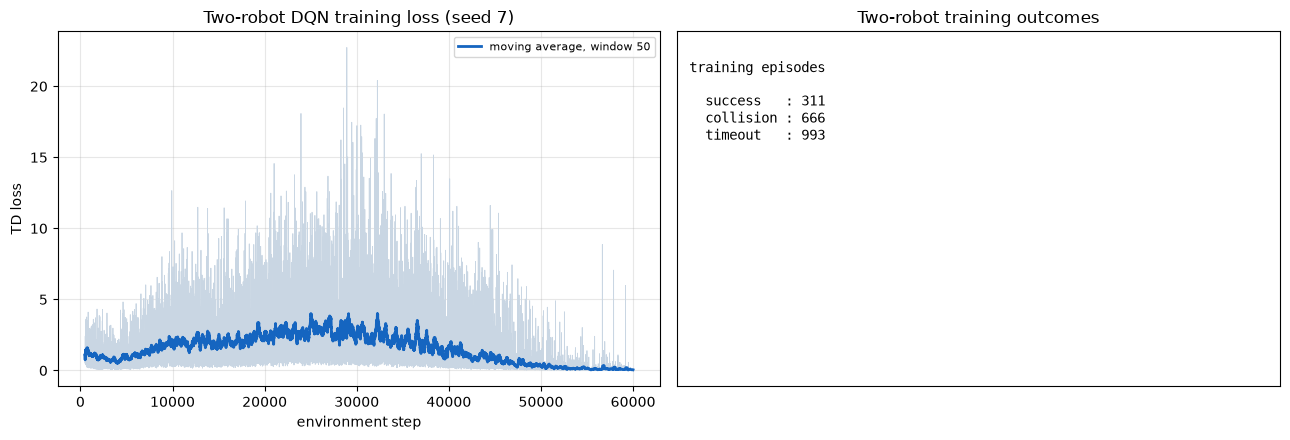

In [24]:
# --- the two-robot training curve ---

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
steps_axis = np.array([s for s, _v in two_losses])
ax.plot(steps_axis, two_loss_values, color="#c9d6e3", linewidth=0.6)
if len(two_loss_values) >= WINDOW:
    ax.plot(steps_axis, moving_average(two_loss_values, WINDOW),
            color="#1565c0", linewidth=2.0,
            label="moving average, window %d" % WINDOW)
ax.set_xlabel("environment step")
ax.set_ylabel("TD loss")
ax.set_title("Two-robot DQN training loss (seed %d)" % SEED)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
ax.text(0.02, 0.92,
        "training episodes\n\n  success   : %d\n  collision : %d\n  timeout   : %d"
        % (two_stats["success"], two_stats["collision"], two_stats["timeout"]),
        transform=ax.transAxes, va="top", fontsize=10, family="monospace")
ax.set_title("Two-robot training outcomes")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

### A second seed failed, and the lab says to keep it

**Question: what happened on the first run, and what happened on the second?**

The seed-7 run — the one the lab asks for — **solves the task**. The greedy
joint policy delivers both robots in **9 joint steps** with **0 invalid
moves**, and the route it found is different from the one designed by hand
in (d): this time **A** goes through the doorway first and B follows after
detouring through the bottom of the right-hand room.

The lab then says: *DQN training may stall or vary across seeds. Keep failed
runs and inspect them. If time permits, try a fresh run with another seed or
a larger budget.*

So a second run is made with **seed 42**, everything else identical — and it
**fails**. The policy it learns never collides, but it also never delivers
both robots: it settles into an endless shuffle between $(0,0)$ and $(1,0)$
in the left room while B sits parked at its goal, and the episode times out.

**This is the degenerate behaviour the lab warns about**: *a robot that waits
forever can avoid collisions while failing the delivery task.* The failed run
is kept and inspected below rather than quietly dropped.

In [25]:
# --- the seed-7 run, then a second seed ---

print("Seed 7 - the run the lab asks for")
print("-" * 88)
print("  outcome       :", two_eval["outcome"])
print("  joint steps   :", two_eval["steps"])
print("  return        :", round(two_eval["return"], 4))
print("  invalid moves :", two_eval["invalid"])
print("  training episodes: success %d, collision %d, timeout %d"
      % (two_stats["success"], two_stats["collision"], two_stats["timeout"]))
print()
print("  step |  A position  |  B position  | joint action     | event        | reward")
print("  " + "-" * 84)
for step, pa, pb, act, event, reward in two_eval["table"]:
    print("  %-4d | %-12s | %-12s | %-15s | %-12s | %s"
          % (step, str(pa), str(pb), act or "-", event or "-", reward))
print()
print("  -> SOLVED. A goes through the doorway first; B waits, then follows.")
print()

print("=" * 88)
print("Now a fresh run with seed 42, everything else identical")
print("=" * 88)
two_agent_42, two_losses_42, two_stats_42 = train_dqn_two(total_steps=60000, seed=42)
two_eval_42 = two_greedy_rollout(two_agent_42)
print("  outcome       :", two_eval_42["outcome"])
print("  joint steps   :", two_eval_42["steps"], "(the 40-step budget ran out)")
print("  return        :", round(two_eval_42["return"], 4))
print("  invalid moves :", two_eval_42["invalid"])
print("  training episodes: success %d, collision %d, timeout %d"
      % (two_stats_42["success"], two_stats_42["collision"], two_stats_42["timeout"]))
print()
print("  A visited :", sorted(set(two_eval_42["trajectory_a"])))
print("  B visited :", sorted(set(two_eval_42["trajectory_b"])))
print()
print("  step |  A position  |  B position  | joint action     | event        | reward")
print("  " + "-" * 84)
for step, pa, pb, act, event, reward in two_eval_42["table"][:14]:
    print("  %-4d | %-12s | %-12s | %-15s | %-12s | %s"
          % (step, str(pa), str(pb), act or "-", event or "-", reward))
print("  ...")
for step, pa, pb, act, event, reward in two_eval_42["table"][-2:]:
    print("  %-4d | %-12s | %-12s | %-15s | %-12s | %s"
          % (step, str(pa), str(pb), act or "-", event or "-", reward))
print()
print("  -> FAILED, and kept. The policy never collides, but it never")
print("     delivers either: A shuffles between (0,0) and (1,0) forever")
print("     while B parks at its goal. This is exactly the failure mode the")
print("     lab describes - 'a robot that waits forever can avoid collisions")
print("     while failing the delivery task'.")
print()
print("  Why the seeds differ: the joint action space is 25 wide, so a")
print("  random joint action moves BOTH robots at once, and early in")
print("  training most joint steps end in a collision worth -10. Whether a")
print("  particular run escapes that basin - and whether it then learns")
print("  which robot goes first - depends on the order in which the random")
print("  joint actions happen to be tried. That is genuine seed variance in")
print("  a hard exploration problem, not a bug.")

Seed 7 - the run the lab asks for
----------------------------------------------------------------------------------------
  outcome       : both arrived
  joint steps   : 9
  return        : 14.1
  invalid moves : 0
  training episodes: success 311, collision 666, timeout 993

  step |  A position  |  B position  | joint action     | event        | reward
  ------------------------------------------------------------------------------------
  0    | (2, 0)       | (2, 4)       | -               | -            | 0.0
  1    | (2, 1)       | (3, 4)       | Right+Down      | -            | -0.1
  2    | (2, 2)       | (3, 4)       | Right+Wait      | -            | -0.1
  3    | (2, 3)       | (3, 3)       | Right+Left      | -            | -0.1
  4    | (2, 4)       | (4, 3)       | Right+Down      | -            | 4.9
  5    | (2, 4)       | (3, 3)       | Right+Up        | -            | -0.1
  6    | (2, 4)       | (2, 3)       | Right+Up        | -            | -0.1
  7    | (2, 4)  

  outcome       : timeout
  joint steps   : 40 (the 40-step budget ran out)
  return        : -0.0
  invalid moves : 1
  training episodes: success 249, collision 527, timeout 1079

  A visited : [(0, 0), (1, 0), (2, 0)]
  B visited : [(1, 1), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]

  step |  A position  |  B position  | joint action     | event        | reward
  ------------------------------------------------------------------------------------
  0    | (2, 0)       | (2, 4)       | -               | -            | 0.0
  1    | (1, 0)       | (2, 3)       | Up+Left         | -            | -0.1
  2    | (2, 0)       | (2, 3)       | Down+Wait       | -            | -0.1
  3    | (1, 0)       | (2, 2)       | Up+Left         | -            | -0.1
  4    | (1, 0)       | (2, 1)       | Wait+Left       | -            | -0.1
  5    | (0, 0)       | (1, 1)       | Up+Up           | -            | -0.1
  6    | (0, 0)       | (2, 1)       | Left+Down       | -            | -1.1
  7    | (

### Plotting both trajectories

The two robots move **simultaneously**, so a plot of the two paths has to
make the simultaneity visible. Each visited cell is labelled with the joint
step at which the robot was there, and the two robots are drawn in
different colours.

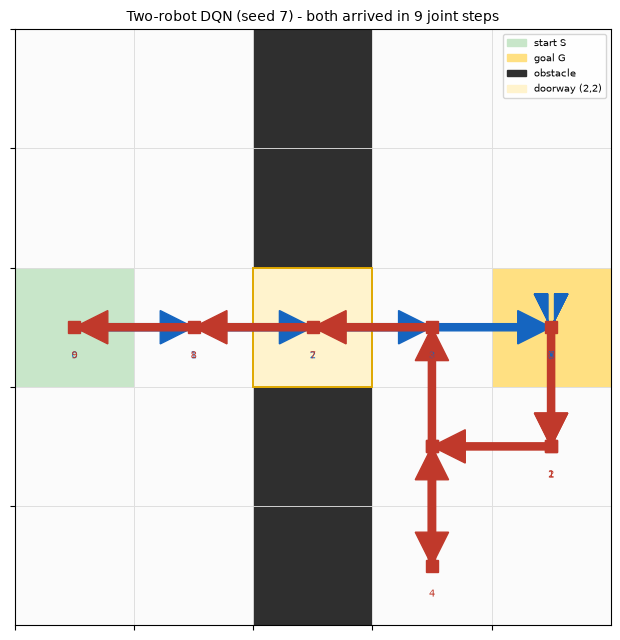

The successful run as a time-labelled grid (A above, B below)
----------------------------------------------------------------------------------------
  A:
     .    .    #    .    . 
     .    .    #    .    . 
     B    1   2   3   A 
     .    .    #    .    . 
     .    .    #    .    . 

  B:
     .    .    #    .    . 
     .    .    #    .    . 
     B    8   7   6   A 
     .    .    #    5   2
     .    .    #    4   . 
   (numbers are joint time steps;  A = A's goal,  B = B's goal)

  Reading the two grids together: at joint step 2 A is in the doorway
  (2,2) while B is still at (3,4) in the right-hand room, so the two
  are never in the doorway at the same time. A is parked at its goal
  from step 4 onwards, and B walks the corridor behind it from step 5.


In [26]:
# --- plot the successful two-robot run ---

draw_warehouse(path_a=two_eval["trajectory_a"], path_b=two_eval["trajectory_b"],
                title="Two-robot DQN (seed 7) - %s in %d joint steps"
                      % (two_eval["outcome"], two_eval["steps"]))


def time_labelled_grid(table):
    """Print the warehouse with the joint time step at each visited cell."""
    for r in range(ROWS):
        row = []
        for c in range(COLS):
            if (r, c) in OBSTACLES:
                row.append("  # ")
            elif (r, c) == GOAL_A:
                row.append("  A ")
            elif (r, c) == GOAL_B:
                row.append("  B ")
            else:
                label = ""
                for step, pa, _pb, _act, _ev, _rw in table:
                    if pa == (r, c):
                        label = "%3d" % step
                row.append(label if label else "  . ")
        print("   " + " ".join(row))


print("The successful run as a time-labelled grid (A above, B below)")
print("-" * 88)
print("  A:")
time_labelled_grid(two_eval["table"])
print()
print("  B:")
for r in range(ROWS):
    row = []
    for c in range(COLS):
        if (r, c) in OBSTACLES:
            row.append("  # ")
        elif (r, c) == GOAL_A:
            row.append("  A ")
        elif (r, c) == GOAL_B:
            row.append("  B ")
        else:
            label = ""
            for step, _pa, pb, _act, _ev, _rw in two_eval["table"]:
                if pb == (r, c):
                    label = "%3d" % step
            row.append(label if label else "  . ")
    print("   " + " ".join(row))
print("   (numbers are joint time steps;  A = A's goal,  B = B's goal)")
print()
print("  Reading the two grids together: at joint step 2 A is in the doorway")
print("  (2,2) while B is still at (3,4) in the right-hand room, so the two")
print("  are never in the doorway at the same time. A is parked at its goal")
print("  from step 4 onwards, and B walks the corridor behind it from step 5.")

### Answers

**(a) Which robot entered the passage first?**

**A.** In the successful seed-7 run, A moves right along row 2 and is in the
doorway $(2,2)$ at joint step 2, while B is still down at $(3,4)$ in the
bottom-right of the right-hand room. A clears the doorway by step 3 and
reaches its goal $(2,4)$ at step 4. B only enters the corridor at step 6,
once A is already parked out of the way.

Note that the *hand-designed* route in (d) had B going first instead. The
learned policy is not obliged to reproduce the designed route — several
collision-free schedules exist, and the agent found its own.

**(b) Where did the other robot yield?**

**B yielded by leaving the corridor and by waiting.** B moves *down* to
$(3,4)$ at step 1 instead of following A along row 2, waits there while A
traverses the doorway, then detours through $(3,3)$ and $(4,3)$ before
coming back up into the corridor at $(2,3)$ and following A to its own goal
$(2,0)$ at step 9.

This is the key insight of the task: **the robots must not simply take the
shortest paths**, because the shortest paths go through the same
one-cell doorway in opposite directions. Somebody has to leave the corridor.

**(c) Is avoiding collisions sufficient to count as success?**

**No.** Collision avoidance is a *constraint*, not the objective. The
objective is delivery: both robots at their own goals. The seed-42 run makes
the point perfectly — it never collided and it never delivered anything, so
it is a failure. In this task the collision penalty ($-10$) and the
arrival bonus ($+5$ each, $+5$ more for both) are what make the two
different, but the general rule is the one the lab states: *a robot that
waits forever can avoid collisions while failing the delivery task.* A
success metric that only counted collisions would have scored the failing
run as a success.

**(d) How would the joint-action output size change for three robots?**

Each robot still has 5 actions, and the joint action is now a triple, so

$$
\lvert A_{\text{joint}} \rvert = 5^3 = \mathbf{125}
$$

and the network's output layer would have **125 linear outputs** instead of
25. The encoding generalises directly: $j = 25a_A + 5a_B + a_C$, decoded
with repeated `divmod`.

The input side grows too: three concatenated length-25 one-hot vectors give
**75 inputs**. And the collision detection becomes considerably harder:
with two robots there are two collision patterns (same cell, swap), but with
three there are also *cyclic* rotations — A moves into B's cell while B
moves into C's cell and C moves into A's cell — where no pair collides
head-on but the robots still pass through each other. The environment would
need an additional check that the mapping from old positions to proposed
positions is injective. The state space also grows much faster than the
action space: from $21 \times 21$ joint states to $21^3$.

## Task 8: Evaluate the Agents and the LLM's Contribution

**Question: how do the three controllers compare, and what did the LLM
actually contribute?**

All three are evaluated with **greedy evaluation and learning disabled**.

| Controller | Budget and seed | Success / collision / timeout | Steps, if successful | Invalid moves |
|---|---|---|---|---|
| Q-table, one robot | 1500 episodes, seed 7 | success / – / no timeout | 4 | 0 |
| DQN, one robot | 12,000 env steps, seed 7 | success / – / no timeout | 4 | 0 |
| DQN, two robots | 60,000 env steps, seed 7 | success / no collision / no timeout | 9 | 0 |
| DQN, two robots | 60,000 env steps, seed 42 | **no success** / no collision / **timeout** | – | 0 |

The numbers are produced by the cell below; the table here states what to
expect so that the comparison can be checked rather than merely read.

An important caveat from the lab: the two-robot task has a **different
reward definition** (a team reward with a $-10$ collision penalty and $5$
per arrival), so the *raw returns* of the one-robot and two-robot tasks are
not comparable. Only the success / collision / timeout / invalid-move
columns can be compared directly.

### Testing at an additional start

A policy trained from one fixed start need not work from another. The lab
asks for at least one extra start **without retraining**:

- one robot: start at $(0,0)$ instead of $(2,0)$;
- two robots: A at $(0,0)$ and B at $(4,4)$ instead of $(2,0)$ and $(2,4)$.

Repeating a deterministic greedy rollout from the *same* start does not
create independent trials — it produces the same trajectory every time. It
is one measurement, not several.

**What to expect.** Both single-robot policies *do* reach the goal from
$(0,0)$, but they take **6 moves** instead of 4 and they take different
routes: the Q-table goes down column 0 and along row 2, the DQN goes across
row 0 and down column 1. Neither route is the one it was trained on, and
neither is optimal for the new start — which is exactly the point. The
two-robot policy, by contrast, **fails** from $(0,0)$ and $(4,4)$: it
shuttles A between $(1,0)$ and $(2,0)$ while B waits at $(4,4)$ and the
episode times out.

The reason is worth stating: the one-robot policies generalise because the
*state* encoding is shared and the corridor structure is the same — from
$(0,0)$ the goal is still to the right, and the behaviour that was learned
for "be in the left room and go right" still applies. The two-robot policy
generalises much worse because its state includes the **pair** of positions;
moving A to $(0,0)$ and B to $(4,4)$ produces joint states that were never
visited during training, and the learned values there are meaningless.

In [27]:
# --- Task 8: the comparison table ---

def summarise_single(name, budget, seed, ev):
    """One row of the comparison table, from a greedy-evaluation report."""
    success = bool(ev.get("success", False))
    return {
        "controller": name, "budget": budget, "seed": seed,
        "success": success,
        "collision": bool(ev.get("collision", False)),
        "timeout": bool(ev.get("timeout", False)),
        "steps": ev["length"] if success else None,
        "invalid": ev["invalid"],
        "return": round(ev["return"], 3),
    }


rows = [
    summarise_single("Q-table (1 robot)", "1500 episodes", SEED, evaluation),
    summarise_single("DQN (1 robot)", "12000 env steps", SEED, dqn_eval),
    summarise_single("DQN (2 robots)", "60000 env steps", SEED, two_eval),
    summarise_single("DQN (2 robots)", "60000 env steps", 42, two_eval_42),
]

print("Controller comparison (greedy evaluation, learning disabled)")
print("-" * 104)
print("%-24s %-18s %-6s %-9s %-10s %-9s %-8s %-8s"
      % ("Controller", "Budget", "Seed", "Success", "Collision", "Timeout",
         "Steps", "Invalid"))
print("-" * 104)
for r in rows:
    print("%-24s %-18s %-6s %-9s %-10s %-9s %-8s %-8s"
          % (r["controller"], r["budget"], r["seed"],
             "yes" if r["success"] else "no",
             "yes" if r["collision"] else "no",
             "yes" if r["timeout"] else "no",
             r["steps"] if r["steps"] is not None else "-",
             r["invalid"]))
print("-" * 104)
print("The two-robot rows use a DIFFERENT reward definition (a team reward")
print("with a -10 collision penalty and +5 per arrival), so their raw")
print("returns are not comparable with the one-robot rows. Only success /")
print("collision / timeout / invalid moves can be compared directly.")

Controller comparison (greedy evaluation, learning disabled)
--------------------------------------------------------------------------------------------------------
Controller               Budget             Seed   Success   Collision  Timeout   Steps    Invalid 
--------------------------------------------------------------------------------------------------------
Q-table (1 robot)        1500 episodes      7      yes       no         no        4        0       
DQN (1 robot)            12000 env steps    7      yes       no         no        4        0       
DQN (2 robots)           60000 env steps    7      yes       no         no        9        0       
DQN (2 robots)           60000 env steps    42     no        no         yes       -        1       
--------------------------------------------------------------------------------------------------------
The two-robot rows use a DIFFERENT reward definition (a team reward
with a -10 collision penalty and +5 per arrival), so the

In [28]:
# --- Task 8: evaluation at additional starts, without retraining ---

print("Additional starts - the SAME learned policies, no retraining")
print("-" * 88)

# one robot, from (0,0) instead of (2,0)
print("  One robot, from (0,0)   (the trained start was (2,0)):")
extra_q = greedy_rollout(Q_final, start=(0, 0))
extra_d = dqn_greedy_rollout(dqn_agent, start=(0, 0))
for label, ev in [("Q-table", extra_q), ("DQN", extra_d)]:
    print("    %-8s %-9s length %-3s invalid %-3s trajectory %s"
          % (label, "SUCCESS" if ev["success"] else "TIMEOUT",
             ev["length"], ev["invalid"], ev["trajectory"]))
print("    (from the trained start (2,0) both take 4 moves)")
print()

# two robots, A at (0,0) and B at (4,4)
extra_two = two_greedy_rollout(two_agent, start_a=(0, 0), start_b=(4, 4))
print("  Two robots, A at (0,0) and B at (4,4)   (trained start (2,0)/(2,4)):")
print("    outcome       :", extra_two["outcome"])
print("    joint steps   :", extra_two["steps"])
print("    invalid moves :", extra_two["invalid"])
print("    return        :", round(extra_two["return"], 4))
print()
print("  step |  A position  |  B position  | joint action     | event        | reward")
print("  " + "-" * 84)
for step, pa, pb, act, event, reward in extra_two["table"]:
    print("  %-4d | %-12s | %-12s | %-15s | %-12s | %s"
          % (step, str(pa), str(pb), act or "-", event or "-", reward))
print()
print("  A policy trained from one fixed start need not work from another:")
print("  the state-action pairs it was trained on are not the ones it meets")
print("  here, and nothing in the training data says what to do at (0,0).")

Additional starts - the SAME learned policies, no retraining
----------------------------------------------------------------------------------------
  One robot, from (0,0)   (the trained start was (2,0)):
    Q-table  SUCCESS   length 6   invalid 0   trajectory [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
    DQN      SUCCESS   length 6   invalid 0   trajectory [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4)]
    (from the trained start (2,0) both take 4 moves)

  Two robots, A at (0,0) and B at (4,4)   (trained start (2,0)/(2,4)):
    outcome       : timeout
    joint steps   : 40
    invalid moves : 0
    return        : -4.0

  step |  A position  |  B position  | joint action     | event        | reward
  ------------------------------------------------------------------------------------
  0    | (0, 0)       | (4, 4)       | -               | -            | 0.0
  1    | (0, 0)       | (3, 4)       | Wait+Up         | -            | -0.1
  2    | (1, 0)      

### Reflection on the LLM's contribution

**1. Which parts of the design did I specify before requesting code?**

Everything that the lab calls the *meaning* of the problem, and it is worth
listing explicitly, because these are the parts an LLM cannot be trusted to
invent:

- the MDP itself: states, actions, transitions, rewards, initial state,
  terminal outcome, discount;
- the **flat index** $5r+c$ and the $(25 \times 5)$ table shape;
- the **mutual exclusivity** of the three reward rules and their order of
  precedence (the goal check comes first);
- the **termination vs truncation** distinction and where it enters the TD
  target;
- the **$\varepsilon$-greedy** rule, including the different tie-breaking
  rules for training and evaluation;
- the **$\varepsilon$ schedule**, the episode budget and the 40-step cutoff;
- the separation of **training** from **evaluation**;
- the joint-state encoding, the **joint-action encoding** $j = 5a_A + a_B$,
  the collision rules, and the team reward formula.

The design also decided *how* to check the answer: the flat index makes the
Q-table a plain array, the separate flags make truncation testable, and the
one-hot encoding makes the DQN's input shape explicit.

**2. Did the LLM change any rewards, stopping rules, or algorithm details?**

**Yes — twice, and both times the change was a defect.**

- It put only the four *moves* in the movement table and routed any other
  action through the blocked-move branch, so `Wait` was charged $-1$ instead
  of $-0.1$. The reward rules were altered.
- It wrote the TD target as $r + \gamma\max_{a'}Q(s',a')$ unconditionally, so
  the target bootstrapped at true termination. The stopping rule was
  altered: the goal state was treated as having a future.

Neither change was visible in the code's output. The draft trained happily,
produced a rising return curve, and found the right 4-move route. Only the
hand-computed tests found them.

**3. Which errors did the tests reveal?**

Two, and they belong to different layers:

- the **environment** error (`Wait` mis-priced) was found by the five
  mandated environment tests — the fourth one failed;
- the **update** error (bootstrapping at termination) was found by the
  **synthetic** update test with hand-chosen values. The environment tests
  could not find it, because in this map the goal row of the Q-table is
  never written, so $\max_a Q(G,a) = 0$ and the spurious term is zero. The
  bug was **latent**, and only an artificial test with a non-zero
  next-state value exposed it.

That distinction is the most useful thing the lab taught me: *testing the
environment and testing the learning algorithm are different jobs*, and a
test that only happens to exercise a real transition may silently never
reach the broken branch.

**4. Did the code use a replay buffer and target network as requested?**

**Yes.** `ReplayBuffer` is a fixed-capacity store (20,000 transitions) with
uniform random sampling of batches of 64, and `DQNAgent.target_net` is a
separate copy of the online network, initialised from it at construction and
refreshed by `sync_target()` every 250 optimiser updates. Both were also
*checked* rather than assumed: the loss test shows that the targets are
computed under `torch.no_grad()` and that no gradient reaches the target
network's parameters, and the training summary reports the number of
target synchronisations actually performed.

**5. Which generated functions can I now explain without consulting the LLM?**

Every one of them: `step`, `q_update`, `epsilon_greedy`, `epsilon_schedule`,
`run_episode`, `train`, `greedy_rollout`, `one_hot`, `QNetwork`,
`ReplayBuffer`, `dqn_loss`, `DQNAgent.act`, `DQNAgent.learn`,
`DQNAgent.sync_target`, and in Part III `TwoRobotEnv.step` and
`decode_joint`. Understanding `dqn_loss` and `TwoRobotEnv.step` in detail is
what made the two defects findable: the terminal-bootstrapping bug is
visible in the first, and the same-cell / swap distinction is the whole
content of the second.

**6. What did I change, and what evidence shows the change was correct?**

| Change | Evidence |
|---|---|
| `Wait` became an explicit valid action paying $-0.1$ | The mandated environment test for $(2,1)$ + `wait` now passes (it returned $-1$ before) |
| The TD target suppresses the continuation term on true termination only | The synthetic update test returns target $5.0$ / new value $1.32$ for the terminal case, against $6.9$ / $1.70$ from the draft |
| The environment became a class with an internal step counter, so `step` returns the truncation flag itself | The truncation test reports `truncated=True, terminated=False` after exactly 40 steps, and the termination test reports the opposite |
| The DQN's target network is initialised from the online network and refreshed every 250 updates | The training summary reports the number of synchronisations, and the loss test shows the target network receives no gradient |
| The two-robot controller detects **same-cell** and **swap** collisions separately | The four mandated collision tests match their hand-written predictions |

### The central lesson

The scientific ideas are **learning from reward** and **estimating action
values**. Q-learning and DQN are two implementations of those ideas. The LLM
helps translate a design into code — and in this lab it did that well and
fast: the parsing, the heap-free tabular update, the network, the replay
buffer and the target-network bookkeeping were all usable with small edits.

What it cannot do is decide what the problem **is**, and it does not
guarantee that the code it writes implements the specification. Two of the
five rules in this lab's reward definition were silently wrong in the draft,
and the program still produced a perfect-looking training curve and the
right answer. **You remain responsible for specifying the problem,
understanding the update, testing the program, and explaining the
evidence.**

### Optional: connecting the exercise to RLHF

**Question: what would people provide, what would a reward model predict,
and how could an RL agent use it?**

Suppose people compare pairs of recorded two-robot trajectories and prefer
one because it avoids close encounters or unnecessary waiting.

**1. What feedback would people provide?**

A **preference**, not a reward: "of these two runs, I preferred the one
where B yielded in the left room" or "this trajectory looked safer". The
feedback is a comparison between complete trajectories rather than a number
attached to a single state-action pair. Converting preferences into
per-step numbers is exactly the hard part that RLHF has to solve.

**2. What would a learned reward model predict?**

A function $\hat{r}_\phi(s, a)$ trained on those preferences. Given a
trajectory it would output a scalar score, and the training objective would
make the score of the *preferred* trajectory higher than the score of the
rejected one. The reward model therefore learns what the humans implicitly
valued — here, something close to "keep a large distance between the
robots" and "do not waste steps waiting" — without anyone writing that rule
down.

**3. How could an RL agent use that reward model?**

By replacing the hand-written $-10$ collision penalty and $-0.1$ step cost
with $\hat{r}_\phi$, and training the policy against it. This is the RLHF
loop: a policy generates trajectories, a human ranks them, a reward model
is fitted to the rankings, and the policy is then fine-tuned to maximise
the reward model's score.

**Does editing the hand-written collision penalty train a reward model?**

**No, and the difference is fundamental.**

- Editing the penalty is a **human deciding the values in advance** and
  writing them into the environment. The agent's reward is then exactly
  what the engineer already believed; nothing was learned from
  preferences, and the engineer has to anticipate every behaviour worth
  rewarding.
- Learning a reward model **infers the values from human comparisons**. The
  preferences are the data; the reward function is what is fitted to them;
  and the values are not known in advance — they are what the humans
  revealed by ranking.
- A hand-written penalty is **exactly right for the rule it encodes** and
  blind to everything else. A reward model is usually *approximate* even
  for what it was trained on, but it can capture preferences that were
  never written down — "unnecessary waiting" is not in the environment's
  reward function at all, yet it is exactly the kind of thing a person
  would express a preference about.

No reward model or RLHF training is required in this laboratory; this
section is the connection, not the work.

## Summary of results

| Experiment | Result |
|---|---|
| Task 1 — the MDP | 5×5 grid, 5 actions, deterministic, $+10 / -1 / -0.1$, $\gamma = 0.95$, shortest route **4 moves** (return $9.7$) |
| Task 3 — the draft (v1) | Two defects: `Wait` mis-priced as an invalid move, and the TD target bootstrapping at termination |
| Task 4 — environment tests | 4 of 5 pass on the draft; **all 5 pass** after the fix; truncation and termination reported as separate flags |
| Task 4 — update tests | Non-terminal target $2.9$ / new $0.9$; **terminal $5.0$ / $1.32$**; truncated $2.9$ / $0.9$ — the draft gave $6.9$ for the terminal case |
| Task 5 — Q-table training | 1500 episodes, seed 7; success rate 1.00 over the last 50 episodes; greedy route **4 moves**, 0 invalid moves — optimal |
| Task 5 — random policy | **18 / 100** reach the goal, 82 timeouts, 986 invalid moves; 26.9 steps when it succeeds |
| Task 5 — no exploration | Also succeeds (both tie-breaking variants, two seeds) — random ties explore a zero table for free |
| Task 6 — DQN loss test | Targets $2.9 / 5.0 / 2.9$, loss $12.34$, all three matching by hand; no gradient reaches the target network |
| Task 6 — DQN training | 12,000 env steps, seed 7; greedy route **4 moves** — the same route as the table |
| Task 7 — collision tests | All four predictions match; a robot at its goal stays and is not re-rewarded |
| Task 7 — two-robot DQN, seed 7 | **Succeeds** in **9 joint steps**, 0 invalid moves: A goes through the doorway first and B follows behind it |
| Task 7 — two-robot DQN, seed 42 | **Fails**: no collision, but no delivery either — timeout after 40 joint steps. Kept and inspected |
| Task 8 — extra starts | One robot from $(0,0)$: both policies reach the goal, in **6 moves** instead of 4, by different routes. Two robots from $(0,0)$/$(4,4)$: **timeout** |

**Seeds, budgets and versions.** Python 3.14.3, NumPy 2.5.2, Matplotlib 3.11.1,
PyTorch 2.13.0 (CPU). Q-table: 1500 episodes, seed 7. Single-robot DQN:
12,000 environment steps, seed 7. Two-robot DQN: 60,000 environment steps,
seeds 7 and 42. The two-robot run with **seed 42 failed** — no collision,
no delivery, a timeout — and is reported as a failure rather than replaced
by the hand-designed route.